# Projet 3 — Advection-diffusion d'un scalaire : mélange thermique dans un tourbillon

**Objectif du TP.** On transporte un champ de température $T(x,y,t)$ dans un écoulement
tourbillonnaire **imposé** (tourbillon de Taylor-Green), en tenant compte de la diffusion
thermique. On compare **trois schémas numériques d'ordres différents** (1, 2 et 3), on mesure
leur **ordre de convergence en maillage**, on donne une **valeur fiable du flux de chaleur
maximal** $\Phi_w^{max}$ sur la paroi droite avec un **intervalle de confiance**, et on compare
leur **coût de calcul à précision égale**.

### Feuille de route (ce qu'on va faire, dans l'ordre)

| Étape | Ce qu'on regarde | Pourquoi |
|---|---|---|
| **1. Comprendre le problème** | champ de vitesse, nombres sans dimension, échelles de temps | savoir *à l'avance* ce qui va être difficile numériquement |
| **2. Discrétiser** | maillage, nœuds fantômes, 3 schémas, stabilité (von Neumann) | construire des schémas dont on connaît les propriétés |
| **3. Résultats 65×65** | cartes de $T$, sonde, flux $\Phi_w(t)$ | ce que demande l'énoncé ; premières comparaisons |
| **4. Convergence en maillage** | erreur vs $\Delta x$, ordres observés | vérifier que chaque schéma a *réellement* l'ordre annoncé |
| **5. $\Phi_w^{max}$ + intervalle de confiance** | Richardson / GCI, écarts entre méthodes | donner un chiffre *et* son incertitude |
| **6. Performance** | erreur vs temps CPU | quel schéma est le plus rentable ? |

> **Convention de lecture.** Chaque étape suit le même schéma : *ce qu'on regarde* →
> *ce qu'on s'attend à voir (et pourquoi)* → *code* → *lecture des résultats*. Prendre le
> temps de formuler une **prédiction avant chaque calcul** est la meilleure façon de
> comprendre : quand le résultat la contredit, c'est là qu'on apprend quelque chose
> (et il y aura une vraie surprise à l'étape 4).

In [1]:
# Import & Environment
import time
import numpy as np
import matplotlib.pyplot as plt
from numba import jit

# Style des figures : une couleur FIXE par schéma (jamais réattribuée d'une figure à l'autre),
# doublée d'un marqueur / style de ligne pour rester lisible sans la couleur.
COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a", "ref": "#52514e"}
MARKERS = {1: "o", 2: "s", 3: "^"}
NAMES = {1: "Schéma 1 (ordre 1)", 2: "Schéma 2 (ordre 2)", 3: "Schéma 3 (ordre 3)"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
CMAP_T = "inferno"      # magnitude (température) : échelle séquentielle perceptuelle
CMAP_DIFF = "RdBu_r"    # écart signé : échelle divergente, centrée sur 0 (blanc = pas d'écart)

---
# 1. Comprendre le problème avant de coder

## 1.1 Les équations

On résout l'équation d'**advection-diffusion** de la température (section 2 du sujet) :

$$\frac{\partial T}{\partial t} + \underbrace{u\frac{\partial T}{\partial x} + v\frac{\partial T}{\partial y}}_{\text{advection : le fluide transporte } T}
= \underbrace{D\left(\frac{\partial^2 T}{\partial x^2}+\frac{\partial^2 T}{\partial y^2}\right)}_{\text{diffusion : conduction thermique}}$$

avec un champ de vitesse **figé dans le temps** (tourbillon de Taylor-Green, Eq. 1-2) :

$$u(x,y) = -U\sin\frac{\pi x}{L}\cos\frac{\pi y}{L}, \qquad v(x,y) = U\cos\frac{\pi x}{L}\sin\frac{\pi y}{L}$$

**Point important : ce n'est PAS un problème de Navier-Stokes.** La vitesse est donnée
une fois pour toutes ; la seule inconnue est $T$. L'équation est **linéaire** en $T$. Toute la
difficulté vient de la *compétition* entre deux mécanismes de nature mathématique différente :

- l'**advection** est un opérateur **hyperbolique** : l'information se propage le long des
  trajectoires du fluide, à vitesse finie, sans s'atténuer ; une discontinuité reste une
  discontinuité ;
- la **diffusion** est un opérateur **parabolique** : elle lisse instantanément tout le champ,
  elle détruit les gradients.

C'est exactement le thème du cours (« systèmes hyperboliques / paraboliques ») : les bons
schémas pour l'un ne sont pas les bons pour l'autre.

**Paramètres** : $L=0.3$ m, $U=0.1$ m/s, $D=\lambda/(\rho c_p)=2.5\times10^{-5}$ m²/s,
$\lambda=0.03$ W/m/K, $T_1=400$ K, $T_2=300$ K, $t_{max}=40$ s.
On en déduit au passage $\rho c_p=\lambda/D=1200$ J/m³/K (c'est de l'air : $1.2\times1000$).

In [2]:
# Paramètres physiques (sections 1-3 du sujet)
L = 0.3          # taille du domaine carré [m]
U = 0.1          # amplitude de la vitesse [m/s]
D = 2.5e-5       # diffusivité thermique [m^2/s]
lam = 0.03       # conductivité thermique [W/m/K]
rho_cp = lam / D # capacité thermique volumique [J/m^3/K] (déduite : D = lam / (rho cp))
T1 = 400.0       # température initiale à gauche (x < L/2) [K]
T2 = 300.0       # température initiale à droite, et température imposée en x = L [K]
t_max = 40.0     # durée simulée [s]

print(f"rho*cp = lambda/D = {rho_cp:.0f} J/m^3/K")

rho*cp = lambda/D = 1200 J/m^3/K


## 1.2 Le champ de vitesse : à quoi ressemble l'écoulement ?

**Ce qu'on regarde.** Les lignes de courant et la norme de la vitesse $|\mathbf{u}|$.

**Ce qu'on vérifie (et pourquoi c'est important pour la suite).**

1. **Incompressibilité** $\nabla\cdot\mathbf{u}=0$ : à la main,
   $\partial_x u = -\frac{\pi U}{L}\cos\frac{\pi x}{L}\cos\frac{\pi y}{L}$ et
   $\partial_y v = +\frac{\pi U}{L}\cos\frac{\pi x}{L}\cos\frac{\pi y}{L}$ : la somme est nulle.
   Conséquence : $u\,\partial_x T + v\,\partial_y T = \nabla\cdot(\mathbf{u}T)$ — la forme
   « advective » (celle du sujet) et la forme « conservative » sont équivalentes *dans le continu*.
   (On verra à l'étape 3 qu'elles ne le sont **plus** une fois discrétisées.)
2. **Imperméabilité des parois** : $u=0$ en $x=0$ et $x=L$ ($\sin 0=\sin\pi=0$), $v=0$ en
   $y=0$ et $y=L$. **Aucun fluide n'entre ni ne sort.** La seule façon pour la chaleur de
   quitter le domaine est la **conduction** à travers la paroi droite (isotherme). Les trois
   autres parois sont adiabatiques.
3. **Le sens de rotation**, pour prédire où va aller le fluide chaud.

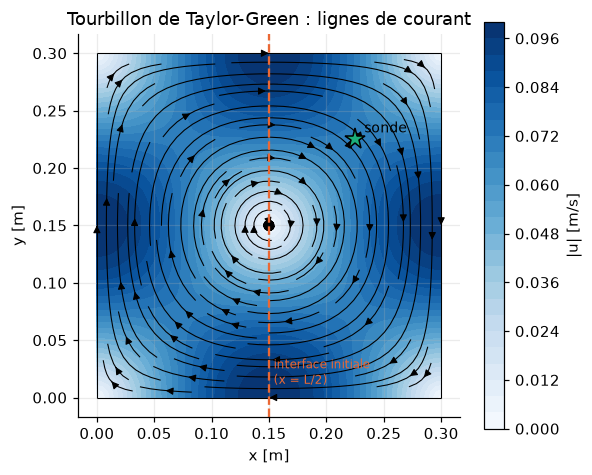

max |div u| (numérique, ~ erreur de troncature) = 8.66e-15 1/s   à comparer à pi*U/L = 1.05 1/s
vitesse max |u| = 0.100 m/s ; max(|u|+|v|) = 0.100 m/s


In [3]:
x_plot = np.linspace(0, L, 61)
X_plot, Y_plot = np.meshgrid(x_plot, x_plot)
u_plot = -U * np.sin(np.pi * X_plot / L) * np.cos(np.pi * Y_plot / L)
v_plot = U * np.cos(np.pi * X_plot / L) * np.sin(np.pi * Y_plot / L)
speed = np.sqrt(u_plot**2 + v_plot**2)

fig, ax = plt.subplots(figsize=(5.6, 4.8))
cf = ax.contourf(X_plot, Y_plot, speed, levels=30, cmap="Blues")
ax.streamplot(x_plot, x_plot, u_plot, v_plot, color="k", linewidth=0.7, density=1.1)
ax.axvline(L / 2, color=COLORS[2], ls="--", lw=1.5)
ax.text(L / 2 + 0.004, 0.012, "interface initiale\n(x = L/2)", color=COLORS[2], fontsize=8)
ax.plot(3 * L / 4, 3 * L / 4, marker="*", ms=14, color=COLORS[3], mec="k")
ax.text(3 * L / 4 + 0.008, 3 * L / 4 + 0.006, "sonde", fontsize=9)
ax.set_aspect("equal"); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title("Tourbillon de Taylor-Green : lignes de courant")
fig.colorbar(cf, label="|u| [m/s]")
plt.show()

# Vérification numérique de la divergence (différences centrées sur une grille fine)
h = x_plot[1] - x_plot[0]
div = np.gradient(u_plot, h, axis=1) + np.gradient(v_plot, h, axis=0)
print(f"max |div u| (numérique, ~ erreur de troncature) = {np.abs(div).max():.2e} 1/s"
      f"   à comparer à pi*U/L = {np.pi * U / L:.2f} 1/s")
print(f"vitesse max |u| = {speed.max():.3f} m/s ; max(|u|+|v|) = {(np.abs(u_plot) + np.abs(v_plot)).max():.3f} m/s")

**Lecture.**

- Un seul gros tourbillon qui tourne dans le **sens horaire** : le fluide monte le long de la
  paroi gauche ($v>0$ pour $x<L/2$), file vers la droite le long du haut, **descend le long de
  la paroi droite**, revient vers la gauche par le bas.
- **Prédiction** : le fluide chaud (à gauche) va monter, longer le haut, et venir **frapper la
  paroi droite froide par le coin supérieur droit**. C'est là que le flux $\Phi_w$ va être
  maximal, et la **sonde** $(3L/4, 3L/4)$, placée sur ce chemin, va voir passer le front chaud
  assez tôt.
- La vitesse est **nulle au centre** (œil du tourbillon) et **aux quatre coins** (points
  d'arrêt) : le fluide au centre tourne sur place très lentement — il ne sera mélangé que par
  diffusion.
- $\max(|u|+|v|) = U$ exactement (car $|\sin a\cos b|+|\cos a\sin b| = |\sin(a\pm b)|\le 1$).
  Ce petit résultat servira pour la condition de stabilité du schéma 1.

## 1.3 Nombres sans dimension et échelles de temps : où est la difficulté ?

Avant tout calcul, on estime les **ordres de grandeur**. C'est ce qui permet de prévoir quel
mécanisme domine, et donc quelles difficultés numériques on va rencontrer.

| Grandeur | Formule | Sens physique |
|---|---|---|
| Temps d'advection | $t_{adv}=L/U$ | temps pour que le fluide traverse le domaine |
| Temps de diffusion | $t_{diff}=L^2/D$ | temps pour que la conduction seule homogénéise le domaine |
| Nombre de Péclet | $Pe = UL/D = t_{diff}/t_{adv}$ | importance de l'advection face à la diffusion |
| Longueur de diffusion | $\ell_D=\sqrt{D\,t_{max}}$ | distance parcourue par la chaleur *par conduction seule* en 40 s |
| Taux d'étirement | $\gamma = \pi U/L$ | vitesse à laquelle le tourbillon étire/amincit les structures (aux points d'arrêt) |
| Épaisseur d'équilibre | $\delta = \sqrt{D/\gamma}$ | épaisseur d'un filament quand étirement et diffusion s'équilibrent |
| Péclet de maille | $Pe_{\Delta x}=U\Delta x/D$ | le maillage « voit-il » la diffusion physique ? |

In [4]:
t_adv = L / U
t_diff = L**2 / D
Pe = U * L / D
ell_D = np.sqrt(D * t_max)
gamma = np.pi * U / L
delta = np.sqrt(D / gamma)
dx_65 = L / 64

print(f"t_adv  = L/U         = {t_adv:8.2f} s")
print(f"t_diff = L^2/D       = {t_diff:8.0f} s   (= {t_diff/60:.0f} min)")
print(f"Pe     = U L / D     = {Pe:8.0f}")
print(f"t_max / t_adv        = {t_max / t_adv:8.1f}   (nombre de 'traversées' pendant la simulation)")
print(f"ell_D = sqrt(D tmax) = {ell_D*1e3:8.1f} mm  (sur L = {L*1e3:.0f} mm)")
print(f"gamma = pi U / L     = {gamma:8.3f} 1/s")
print(f"delta = sqrt(D/gamma)= {delta*1e3:8.2f} mm")
print(f"maillage 65x65 : dx = {dx_65*1e3:.2f} mm  ->  Pe_dx = U dx / D = {U * dx_65 / D:.1f}"
      f"   ;  delta / dx = {delta / dx_65:.2f} maille(s)")

t_adv  = L/U         =     3.00 s
t_diff = L^2/D       =     3600 s   (= 60 min)
Pe     = U L / D     =     1200
t_max / t_adv        =     13.3   (nombre de 'traversées' pendant la simulation)
ell_D = sqrt(D tmax) =     31.6 mm  (sur L = 300 mm)
gamma = pi U / L     =    1.047 1/s
delta = sqrt(D/gamma)=     4.89 mm
maillage 65x65 : dx = 4.69 mm  ->  Pe_dx = U dx / D = 18.8   ;  delta / dx = 1.04 maille(s)


**Lecture — ces chiffres racontent toute l'histoire du TP.**

1. **$Pe = 1200 \gg 1$ : l'advection domine largement.** Sur 40 s, la conduction seule ne
   déplacerait la chaleur que de $\ell_D\approx 3$ cm : sans tourbillon, la chaleur ne
   diffuserait que dans une bande étroite autour de l'interface, sur un domaine de 30 cm. Le
   mélange resterait très local. C'est le **brassage** par le tourbillon qui
   mélange : il enroule l'interface chaud/froid en spirale, l'**étire** et l'**amincit**, ce
   qui crée de forts gradients sur lesquels la diffusion devient efficace. C'est exactement
   le mécanisme du mélange turbulent évoqué en introduction du sujet.

2. **L'épaisseur des filaments tombe à $\delta\approx 5$ mm, soit environ UNE maille du
   maillage 65×65.** Prédiction : le maillage demandé sera **trop grossier pour résoudre
   finement les fronts**, donc les quantités qui dépendent des **gradients** (le flux à la
   paroi !) seront mal capturées à 65×65, tandis qu'une température ponctuelle le sera mieux.
   On le vérifiera.

3. **$Pe_{\Delta x}\approx 19 > 2$ à 65×65.** Résultat classique du cours : un schéma
   **centré** pour l'advection produit des oscillations non physiques dès que
   $Pe_{\Delta x}>2$. On va donc utiliser des schémas **décentrés amont (upwind)** pour
   l'advection. La diffusion, elle, sera discrétisée de façon centrée (c'est naturel pour un
   opérateur parabolique, qui n'a pas de direction privilégiée).

4. $t_{max}/t_{adv}\approx 13$ : le fluide fait plusieurs tours ; on attend une **spirale**
   de plus en plus enroulée.

## 1.4 Conditions initiale et aux limites

- **Initiale** : $T=T_1=400$ K pour $x<L/2$, $T=T_2=300$ K sinon. C'est une **discontinuité**.
  Gardons ce mot en tête : les discontinuités sont le pire ennemi des schémas d'ordre élevé
  (oscillations de Gibbs, perte d'ordre…).
- **Aux limites** :

| Paroi | Condition | Traduction mathématique |
|---|---|---|
| gauche $x=0$ | adiabatique | $\partial T/\partial x = 0$ (Neumann) |
| bas $y=0$, haut $y=L$ | adiabatique | $\partial T/\partial y = 0$ (Neumann) |
| droite $x=L$ | isotherme | $T = T_2$ (Dirichlet) |

**Que va-t-il se passer physiquement ?** Le domaine perd de la chaleur uniquement par la paroi
droite. Le flux sortant par unité de profondeur (en W/m, le problème est 2D) est
$$\Phi_w(t)=\int_0^L\left(-\lambda\frac{\partial T}{\partial x}\right)_{x=L}\,dy .$$
À $t=0$, la paroi droite ne voit que du fluide à $T_2$ : $\Phi_w(0)=0$. Le flux augmente quand
le fluide chaud arrive, passe par un **maximum** $\Phi_w^{max}$, puis diminue au fur et à mesure
que le fluide se mélange et se refroidit. Aux temps très longs ($\sim t_{diff}$), tout le
domaine finit à $T_2$.

**Un outil de contrôle gratuit : le bilan d'énergie.** Comme aucune autre paroi n'échange de
chaleur et qu'aucun fluide ne traverse les parois, l'énergie $E(t)=\rho c_p\iint T\,dA$ ne peut
varier que par la paroi droite :
$$\frac{dE}{dt} = -\Phi_w \quad\Longleftrightarrow\quad \Phi_w(t) = -\rho c_p\,\frac{d}{dt}\iint T\,dx\,dy .$$
Cela donne une **seconde façon, indépendante, de calculer $\Phi_w$** (à partir du champ entier,
sans dériver à la paroi). Si les deux estimations ne sont pas d'accord, l'une des deux est
fausse : on s'en servira comme diagnostic.

---
# 2. Discrétisation

## 2.1 Maillage et nœuds fantômes

**Maillage.** « 65×65 » = 65 points par direction **en comptant les bords**, donc $N=64$
intervalles et $\Delta x=\Delta y=L/64$. Les nœuds sont aux positions $x_i=i\,\Delta x$,
$i=0,\dots,N$ (maillage *aux nœuds*, comme au projet 1). Avantage : les bords, l'interface
$x=L/2$ ($i=N/2$) et la sonde $(3L/4,3L/4)$ ($i=j=3N/4$) tombent **exactement sur des nœuds**
dès que $N$ est multiple de 4 — pas d'interpolation, donc pas d'erreur supplémentaire.

**Nœuds fantômes.** Les schémas d'ordre 2 et 3 ont des stencils qui vont jusqu'à **2 voisins**
($T_{i-2}$, $T_{i+2}$). Au lieu d'écrire des formules spéciales près des bords, on ajoute
**2 rangées de nœuds fictifs** de chaque côté ($G=2$), qu'on remplit à chaque étape pour que
les conditions aux limites soient vérifiées. Le cœur du code reste alors **le même partout**.

**Comment remplir les fantômes ?** Par **symétrie** :

- paroi **adiabatique** ($\partial_n T=0$) : **miroir pair**, $T_{-k}=T_{+k}$ ;
- paroi **isotherme** ($T=T_2$) : **miroir impair** autour de $T_2$, $T_{N+k}=2T_2-T_{N-k}$.

**Pourquoi c'est mieux qu'une simple approximation : c'est EXACT ici.** Regardons la symétrie
du champ de vitesse par rapport à la paroi $x=0$ : $u\propto\sin(\pi x/L)$ est **impaire** en
$x$, $v\propto\cos(\pi x/L)$ est **paire**. L'équation d'advection-diffusion est donc
invariante par la réflexion $x\to -x$ : le prolongement pair de la solution *est lui-même une
solution exacte* du problème prolongé. Même raisonnement en $y=0$, $y=L$ et en $x=L$ (où
$T-T_2$ est prolongé de façon impaire). Les nœuds fantômes ne dégradent donc **pas du tout**
l'ordre des schémas, quel qu'il soit. (Souvenez-vous du projet 1, où un traitement d'ordre 1
de la condition de Neumann faisait perdre l'ordre 2 du schéma global : ici on évite ce piège.)

**Bonus** : comme la vitesse normale est nulle aux parois, il n'y a **aucune condition
« d'entrée »** à gérer pour l'advection.

**Stockage** : le tableau `T` a la taille $(N+1+2G)^2$ ; le nœud physique $(i,j)$ est à
l'indice `T[G + j, G + i]` (ligne = $y$, colonne = $x$, même convention que le projet 1).

In [5]:
G = 2  # nombre de rangées de noeuds fantômes de chaque côté


def build_grid(N):
    # Construit la grille (noeuds physiques + G rangées de noeuds fantômes de chaque côté)
    # et le champ de vitesse analytique (Eq. 1-2) évalué sur TOUS les noeuds, fantômes compris.
    dx = L / N
    x = np.arange(-G, N + G + 1) * dx       # x[G] = 0 et x[G+N] = L
    X, Y = np.meshgrid(x, x)                 # X[j, i] = x[i], Y[j, i] = y[j]
    u = -U * np.sin(np.pi * X / L) * np.cos(np.pi * Y / L)
    v = U * np.cos(np.pi * X / L) * np.sin(np.pi * Y / L)
    return dx, x, X, Y, u, v


def initial_condition(X, interface_value):
    # T = T1 si x < L/2, T2 sinon. La valeur au noeud situé EXACTEMENT sur l'interface
    # x = L/2 est passée en argument : on reviendra sur ce choix à l'étape 4 !
    T = np.where(X < L / 2, T1, T2)
    T[np.isclose(X, L / 2)] = interface_value
    return T


@jit(nopython=True)
def apply_boundary_conditions(T, N):
    # Remplit les noeuds fantômes (et le noeud de Dirichlet) pour imposer les conditions aux limites :
    #   - paroi droite x = L (i = G+N) : T = T2, fantômes en miroir IMPAIR autour de T2
    #   - paroi gauche x = 0 (i = G)   : adiabatique, fantômes en miroir PAIR
    #   - parois bas / haut (j = G, j = G+N) : adiabatiques, miroir PAIR
    # Les colonnes sont traitées en premier, puis les lignes sur toute la largeur
    # (fantômes compris), ce qui remplit correctement les coins.
    n = T.shape[0]
    for j in range(n):
        T[j, G + N] = T2
        for k in range(1, G + 1):
            T[j, G - k] = T[j, G + k]
            T[j, G + N + k] = 2.0 * T2 - T[j, G + N - k]
    for i in range(n):
        for k in range(1, G + 1):
            T[G - k, i] = T[G + k, i]
            T[G + N + k, i] = T[G + N - k, i]


# Petit test de bon sens sur un maillage minuscule
dx_t, x_t, X_t, Y_t, u_t, v_t = build_grid(8)
T_t = initial_condition(X_t, T2)
apply_boundary_conditions(T_t, 8)
print("ligne j = milieu, de gauche à droite (2 fantômes | 9 noeuds physiques | 2 fantômes) :")
print(T_t[G + 4, :])
print(f"u sur la paroi gauche : max |u| = {np.abs(u_t[:, G]).max():.1e} ; "
      f"v sur la paroi basse : max |v| = {np.abs(v_t[G, :]).max():.1e}")

ligne j = milieu, de gauche à droite (2 fantômes | 9 noeuds physiques | 2 fantômes) :
[400. 400. 400. 400. 400. 400. 300. 300. 300. 300. 300. 300. 300.]
u sur la paroi gauche : max |u| = 0.0e+00 ; v sur la paroi basse : max |v| = 0.0e+00


**Lecture du test.** À gauche, les fantômes recopient en miroir les nœuds intérieurs (400, 400) :
gradient nul. À droite, le nœud de bord vaut 300 et les fantômes valent $2\times300-300=300$
(miroir impair) : la paroi impose bien $T_2$. Le nœud d'interface (au milieu) vaut ici $T_2$,
selon la lecture littérale de l'énoncé (« $T_2$ otherwise »). La vitesse normale aux parois est
nulle à la précision machine près.

## 2.2 Méthode des lignes : séparer l'espace et le temps

On discrétise d'abord **en espace** seulement. En chaque nœud, on obtient une équation
différentielle ordinaire :
$$\frac{dT_{i,j}}{dt} = R_{i,j}(T) = -u_{i,j}\,(\delta_x T)_{i,j} - v_{i,j}\,(\delta_y T)_{i,j} + D\,(\delta^2_{xx}T+\delta^2_{yy}T)_{i,j}$$
où $\delta_x$, $\delta^2_{xx}$ sont des approximations des dérivées. Puis on intègre ce gros
système d'EDO **en temps** avec un schéma explicite (Euler, Runge-Kutta). Avantage : on peut
choisir indépendamment la précision en espace et en temps, et analyser chaque partie séparément.

**Règle de conception** : pour que l'**ordre global** soit $p$, il faut que *chaque*
ingrédient soit au moins d'ordre $p$ : advection, diffusion, intégration en temps, conditions
aux limites (réglé par les fantômes exacts), et même le **post-traitement** (dérivée à la
paroi, intégrale du flux). Le maillon le plus faible fixe l'ordre de la chaîne.

On construit donc trois schémas « homogènes » :

| | Advection | Diffusion | Temps | Ordre attendu |
|---|---|---|---|---|
| **Schéma 1** | upwind ordre 1 | centrée ordre 2 | Euler explicite (ordre 1) | **1** |
| **Schéma 2** | upwind ordre 2 (3 points) | centrée ordre 2 | Runge-Kutta 2 (Heun) | **2** |
| **Schéma 3** | upwind-biaisé ordre 3 (4 points) | centrée ordre 4 | Runge-Kutta 3 (SSP) | **3** |

## 2.3 Schéma 1 — Upwind d'ordre 1 + Euler explicite

**Idée du décentrement amont.** L'advection transporte l'information *dans le sens de
l'écoulement*. Pour calculer $\partial T/\partial x$ en un nœud, il est logique d'utiliser le
voisin d'où **vient** le fluide :
$$(\delta_x T)_i = \begin{cases}\dfrac{T_i - T_{i-1}}{\Delta x} & \text{si } u_i>0\\[2mm]
\dfrac{T_{i+1}-T_i}{\Delta x} & \text{si } u_i<0\end{cases}
\qquad
(\delta^2_{xx}T)_i = \frac{T_{i+1}-2T_i+T_{i-1}}{\Delta x^2}$$
puis $T^{n+1}=T^n+\Delta t\,R(T^n)$.

**Propriétés numériques.**

- **Équation équivalente (modifiée)** : en développant en série de Taylor (cas 1D, $u>0$), le
  schéma résout en réalité, à l'ordre dominant,
  $$\partial_t T + u\,\partial_x T = \Big(D + \underbrace{\tfrac{u\Delta x}{2}(1-\mathrm{CFL})}_{D_{num}}\Big)\partial_{xx}T,
  \qquad \mathrm{CFL}=\frac{u\Delta t}{\Delta x}.$$
  L'erreur dominante est une **diffusion numérique** $D_{num}$. À 65×65 :
  $D_{num}\sim U\Delta x/2\approx 2.3\times10^{-4}$ m²/s, soit **~10 fois la diffusivité
  physique** ! Prédiction : le schéma 1 va simuler un fluide beaucoup trop diffusif, avec des
  fronts très étalés et un mélange surestimé.
- **Monotone** : si $\Delta t\,(U/\Delta x + 4D/\Delta x^2)\le 1$, la nouvelle valeur est une
  **combinaison convexe** (coefficients positifs de somme 1) des anciennes. Donc **aucune
  oscillation, aucun dépassement** : $300\le T\le400$ garanti (principe du maximum discret).
  C'est ici qu'on utilise $\max(|u|+|v|)=U$.
- **Stabilité** : la même condition, $\mathrm{CFL}+4\,\mathrm{Fo}\le1$ avec
  $\mathrm{Fo}=D\Delta t/\Delta x^2$.
- **Ordre 1** en espace et en temps.

In [6]:
@jit(nopython=True)
def rhs_upwind1(T, u, v, dx, N, R):
    # Second membre R = -u dT/dx - v dT/dy + D lap(T) du schéma 1 :
    # advection décentrée amont d'ordre 1, diffusion centrée d'ordre 2.
    # Calculé sur tous les noeuds physiques SAUF la paroi droite (Dirichlet, T fixé).
    for j in range(G, G + N + 1):
        for i in range(G, G + N):
            if u[j, i] > 0:
                dTdx = (T[j, i] - T[j, i - 1]) / dx
            else:
                dTdx = (T[j, i + 1] - T[j, i]) / dx
            if v[j, i] > 0:
                dTdy = (T[j, i] - T[j - 1, i]) / dx
            else:
                dTdy = (T[j + 1, i] - T[j, i]) / dx
            lap = (T[j, i + 1] + T[j, i - 1] + T[j + 1, i] + T[j - 1, i] - 4.0 * T[j, i]) / dx**2
            R[j, i] = -u[j, i] * dTdx - v[j, i] * dTdy + D * lap


@jit(nopython=True)
def update_T_method_1(T, u, v, dx, N, dt, R):
    # Un pas de temps du schéma 1 : Euler explicite  T^{n+1} = T^n + dt * R(T^n)
    rhs_upwind1(T, u, v, dx, N, R)
    for j in range(T.shape[0]):
        for i in range(T.shape[1]):
            T[j, i] = T[j, i] + dt * R[j, i]
    apply_boundary_conditions(T, N)

## 2.4 Schéma 2 — Upwind d'ordre 2 + Runge-Kutta 2 (Heun)

**Espace.** On décentre toujours vers l'amont, mais avec **3 points** pour annuler l'erreur
d'ordre 1 (ici pour $u>0$) :
$$(\delta_x T)_i = \frac{3T_i - 4T_{i-1} + T_{i-2}}{2\Delta x} = \partial_x T - \frac{\Delta x^2}{3}\,\partial_{xxx}T + O(\Delta x^3)$$

**Temps** : Runge-Kutta 2 de Heun (*SSP-RK2*, pour *Strong Stability Preserving*) :
$$T^{(1)} = T^n + \Delta t\,R(T^n),\qquad T^{n+1} = \tfrac12 T^n + \tfrac12\left(T^{(1)}+\Delta t\,R(T^{(1)})\right)$$
Pourquoi pas Euler ? Parce qu'Euler explicite est d'ordre 1 en temps (il casserait l'ordre 2),
et surtout parce qu'**Euler + advection d'ordre élevé est instable** : la région de stabilité
d'Euler n'englobe pas les valeurs propres quasi imaginaires pures de l'advection.

**Propriétés numériques.**

- L'erreur dominante est en $\partial_{xxx}T$ : c'est un terme **dispersif** (pas diffusif). Les
  différentes longueurs d'onde se propagent à des vitesses légèrement différentes. Près d'un
  front raide, cela produit des **oscillations parasites** (ondulations, sur/sous-dépassements).
- **Non monotone** : c'est inévitable. **Théorème de Godunov** : un schéma *linéaire* qui
  préserve la monotonie est au plus d'ordre 1. Pour avoir à la fois ordre élevé et monotonie,
  il faut des schémas **non linéaires** (limiteurs, TVD, WENO), hors du périmètre de ce TP.
  Ici, la diffusion physique devrait suffire à amortir les oscillations ; on le vérifiera.
- **Stabilité** : condition plus restrictive que le schéma 1 (calculée à la section 2.6).

In [7]:
@jit(nopython=True)
def rhs_upwind2(T, u, v, dx, N, R):
    # Second membre du schéma 2 : advection décentrée amont d'ordre 2 (stencil à 3 points),
    # diffusion centrée d'ordre 2.
    for j in range(G, G + N + 1):
        for i in range(G, G + N):
            if u[j, i] > 0:
                dTdx = (3.0 * T[j, i] - 4.0 * T[j, i - 1] + T[j, i - 2]) / (2.0 * dx)
            else:
                dTdx = (-3.0 * T[j, i] + 4.0 * T[j, i + 1] - T[j, i + 2]) / (2.0 * dx)
            if v[j, i] > 0:
                dTdy = (3.0 * T[j, i] - 4.0 * T[j - 1, i] + T[j - 2, i]) / (2.0 * dx)
            else:
                dTdy = (-3.0 * T[j, i] + 4.0 * T[j + 1, i] - T[j + 2, i]) / (2.0 * dx)
            lap = (T[j, i + 1] + T[j, i - 1] + T[j + 1, i] + T[j - 1, i] - 4.0 * T[j, i]) / dx**2
            R[j, i] = -u[j, i] * dTdx - v[j, i] * dTdy + D * lap


@jit(nopython=True)
def update_T_method_2(T, u, v, dx, N, dt, R, T_a):
    # Un pas de temps du schéma 2 : Runge-Kutta 2 de Heun (SSP-RK2)
    #   T_a     = T^n + dt R(T^n)
    #   T^{n+1} = 1/2 T^n + 1/2 (T_a + dt R(T_a))
    rhs_upwind2(T, u, v, dx, N, R)
    for j in range(T.shape[0]):
        for i in range(T.shape[1]):
            T_a[j, i] = T[j, i] + dt * R[j, i]
    apply_boundary_conditions(T_a, N)

    rhs_upwind2(T_a, u, v, dx, N, R)
    for j in range(T.shape[0]):
        for i in range(T.shape[1]):
            T[j, i] = 0.5 * T[j, i] + 0.5 * (T_a[j, i] + dt * R[j, i])
    apply_boundary_conditions(T, N)

## 2.5 Schéma 3 — Upwind-biaisé d'ordre 3 + diffusion d'ordre 4 + Runge-Kutta 3

**Espace (advection).** Stencil à 4 points, **légèrement** décentré vers l'amont
(2 points en amont, 1 en aval), pour $u>0$ :
$$(\delta_x T)_i = \frac{2T_{i+1} + 3T_i - 6T_{i-1} + T_{i-2}}{6\Delta x} = \partial_x T + \frac{\Delta x^3}{12}\,\partial_{xxxx}T + O(\Delta x^4)$$

**Espace (diffusion).** Pour ne pas brider l'ordre 3, on prend le laplacien centré d'ordre 4 :
$$(\delta^2_{xx}T)_i = \frac{-T_{i+2}+16T_{i+1}-30T_i+16T_{i-1}-T_{i-2}}{12\Delta x^2}$$

**Temps** : Runge-Kutta 3 SSP de Shu-Osher (3 étapes) :
$$T^{(1)} = T^n+\Delta t R(T^n),\quad T^{(2)}=\tfrac34T^n+\tfrac14\big(T^{(1)}+\Delta tR(T^{(1)})\big),\quad
T^{n+1}=\tfrac13T^n+\tfrac23\big(T^{(2)}+\Delta tR(T^{(2)})\big)$$

**Propriétés numériques.**

- L'erreur dominante, $-\frac{u\Delta x^3}{12}\partial_{xxxx}T$, est une **hyperdiffusion** :
  elle est **dissipative** (bon signe : elle amortit), mais seulement pour les **petites
  longueurs d'onde** (elle croît comme $k^4$). Les grandes structures sont transportées
  presque parfaitement, alors que le bruit à l'échelle de la maille est amorti. C'est le
  meilleur compromis des trois schémas : peu dispersif, juste assez dissipatif.
- Pas monotone non plus (Godunov), mais nettement moins oscillant que le schéma 2.
- La région de stabilité de RK3 contient un morceau de l'axe imaginaire : RK3 accepte des
  pas de temps **plus grands** que RK2 pour l'advection. On va voir que cela compense
  largement l'étape de Runge-Kutta supplémentaire.

In [8]:
@jit(nopython=True)
def rhs_upwind3(T, u, v, dx, N, R):
    # Second membre du schéma 3 : advection décentrée (biaisée amont) d'ordre 3 (stencil à 4 points),
    # diffusion centrée d'ordre 4 (stencil à 5 points).
    for j in range(G, G + N + 1):
        for i in range(G, G + N):
            if u[j, i] > 0:
                dTdx = (2.0 * T[j, i + 1] + 3.0 * T[j, i] - 6.0 * T[j, i - 1] + T[j, i - 2]) / (6.0 * dx)
            else:
                dTdx = (-2.0 * T[j, i - 1] - 3.0 * T[j, i] + 6.0 * T[j, i + 1] - T[j, i + 2]) / (6.0 * dx)
            if v[j, i] > 0:
                dTdy = (2.0 * T[j + 1, i] + 3.0 * T[j, i] - 6.0 * T[j - 1, i] + T[j - 2, i]) / (6.0 * dx)
            else:
                dTdy = (-2.0 * T[j - 1, i] - 3.0 * T[j, i] + 6.0 * T[j + 1, i] - T[j + 2, i]) / (6.0 * dx)
            d2Tdx2 = (-T[j, i + 2] + 16.0 * T[j, i + 1] - 30.0 * T[j, i]
                      + 16.0 * T[j, i - 1] - T[j, i - 2]) / (12.0 * dx**2)
            d2Tdy2 = (-T[j + 2, i] + 16.0 * T[j + 1, i] - 30.0 * T[j, i]
                      + 16.0 * T[j - 1, i] - T[j - 2, i]) / (12.0 * dx**2)
            R[j, i] = -u[j, i] * dTdx - v[j, i] * dTdy + D * (d2Tdx2 + d2Tdy2)


@jit(nopython=True)
def update_T_method_3(T, u, v, dx, N, dt, R, T_a, T_b):
    # Un pas de temps du schéma 3 : Runge-Kutta 3 SSP (Shu-Osher)
    #   T_a     = T^n + dt R(T^n)
    #   T_b     = 3/4 T^n + 1/4 (T_a + dt R(T_a))
    #   T^{n+1} = 1/3 T^n + 2/3 (T_b + dt R(T_b))
    rhs_upwind3(T, u, v, dx, N, R)
    for j in range(T.shape[0]):
        for i in range(T.shape[1]):
            T_a[j, i] = T[j, i] + dt * R[j, i]
    apply_boundary_conditions(T_a, N)

    rhs_upwind3(T_a, u, v, dx, N, R)
    for j in range(T.shape[0]):
        for i in range(T.shape[1]):
            T_b[j, i] = 0.75 * T[j, i] + 0.25 * (T_a[j, i] + dt * R[j, i])
    apply_boundary_conditions(T_b, N)

    rhs_upwind3(T_b, u, v, dx, N, R)
    for j in range(T.shape[0]):
        for i in range(T.shape[1]):
            T[j, i] = T[j, i] / 3.0 + 2.0 / 3.0 * (T_b[j, i] + dt * R[j, i])
    apply_boundary_conditions(T, N)

## 2.6 Analyse de von Neumann : dissipation, dispersion, stabilité

On applique chaque opérateur à un mode de Fourier $T_i=e^{\mathrm{i}k x_i}$, avec
$\theta=k\Delta x\in[0,\pi]$ ($\theta=\pi$ : mode le plus court représentable, 2 mailles par
longueur d'onde). La dérivée exacte donne $\mathrm{i}k\,T$ ; la dérivée discrète donne
$\mathrm{i}k^*\,T$ avec un **nombre d'onde modifié** $k^*$ :

- $\mathrm{Re}(k^*\Delta x)$ vs $\theta$ : si la courbe s'écarte de la diagonale, le mode se
  propage à la mauvaise vitesse → **dispersion** ;
- $\mathrm{Im}(k^*\Delta x)<0$ : le mode est amorti → **dissipation numérique**.

**Ce qu'on attend** : le schéma 1 est très dissipatif dès les grandes longueurs d'onde ; le
schéma 2 est peu dissipatif mais dispersif ; le schéma 3 suit la diagonale plus longtemps et
ne dissipe que les petites échelles.

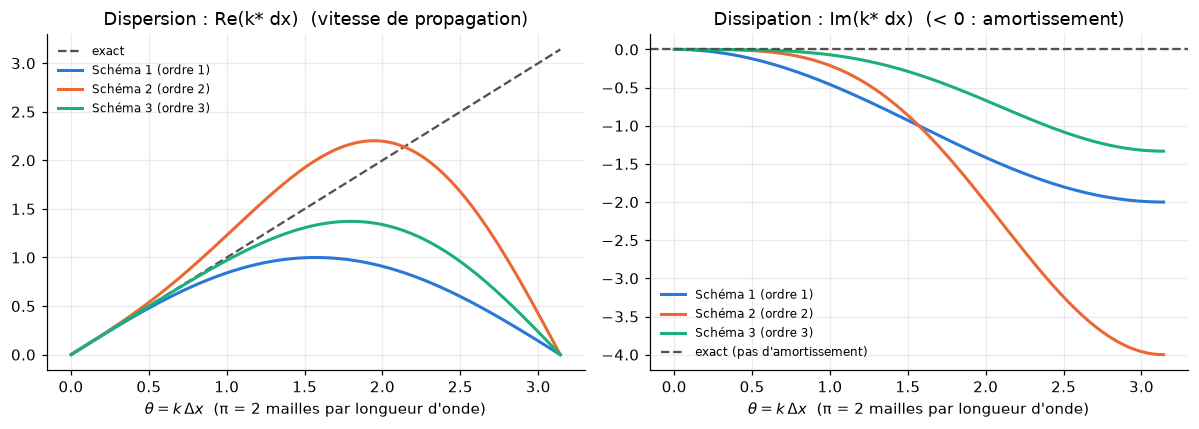

Schéma 1 (ordre 1) : erreur de phase < 1 % tant que lambda >  24.8 mailles
Schéma 2 (ordre 2) : erreur de phase < 1 % tant que lambda >  35.0 mailles
Schéma 3 (ordre 3) : erreur de phase < 1 % tant que lambda >   8.3 mailles


In [9]:
theta = np.linspace(1e-3, np.pi, 300)
E = lambda m: np.exp(1j * m * theta)
# symbole de dx * (delta_x) pour u > 0 ; k* dx = -i * symbole
symbols = {
    1: 1 - E(-1),
    2: (3 - 4 * E(-1) + E(-2)) / 2,
    3: (2 * E(1) + 3 - 6 * E(-1) + E(-2)) / 6,
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(theta, theta, color=COLORS["ref"], ls="--", lw=1.5, label="exact")
for m, s in symbols.items():
    kmod = -1j * s
    axes[0].plot(theta, kmod.real, color=COLORS[m], lw=2, label=NAMES[m])
    axes[1].plot(theta, kmod.imag, color=COLORS[m], lw=2, label=NAMES[m])
axes[1].axhline(0, color=COLORS["ref"], ls="--", lw=1.5, label="exact (pas d'amortissement)")
axes[0].set_title("Dispersion : Re(k* dx)  (vitesse de propagation)")
axes[1].set_title("Dissipation : Im(k* dx)  (< 0 : amortissement)")
for ax in axes:
    ax.set_xlabel(r"$\theta = k\,\Delta x$  (π = 2 mailles par longueur d'onde)")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Points par longueur d'onde pour lesquels l'erreur de phase reste < 1 %
for m, s in symbols.items():
    err = np.abs((-1j * s).real - theta) / theta
    th_ok = theta[np.argmax(err > 0.01)]
    print(f"{NAMES[m]} : erreur de phase < 1 % tant que lambda > {2 * np.pi / th_ok:5.1f} mailles")

**Lecture.**

Il faut lire ces courbes **à petit $\theta$** (modes bien résolus, ceux qui portent la
physique) et **à grand $\theta$** (modes de l'ordre de la maille, qui sont de toute façon du
« bruit » numérique) :

- **Schéma 1** : la dissipation démarre dès les petits $\theta$ (elle croît en $\theta^2$). Les
  structures **bien résolues** sont déjà amorties : c'est la diffusion numérique $D_{num}$.
  Sa dispersion est en revanche modérée.
- **Schéma 2** : dissipation **très faible pour les modes bien résolus** (en $\theta^4$),
  mais **très forte à l'échelle de la maille** ($-4$ en $\theta=\pi$). En dispersion, la courbe
  **dépasse** la diagonale : les ondes moyennes vont **trop vite**, avec une erreur de phase
  deux fois plus grande que celle du schéma 1 à petit $\theta$ ($\theta^2/3$ contre $\theta^2/6$).
  Il faut ~35 mailles par longueur d'onde pour moins de 1 % d'erreur de phase ! Près d'un front
  raide, cela produit des **ondulations** (le front est un mélange de toutes les longueurs
  d'onde, qui se désynchronisent).
- **Schéma 3** : le plus proche de la diagonale (erreur de phase en $\theta^4$), avec une
  dissipation nulle aux grandes longueurs d'onde (en $\theta^4$) et modérée près de $\theta=\pi$.
  Il lui suffit de **~8 mailles par longueur d'onde** pour une erreur de phase < 1 %. C'est tout
  l'intérêt de l'ordre élevé.

*À retenir* : l'ordre d'un schéma décrit son comportement pour les modes **bien résolus**
($\theta\to0$). Ce qui arrive à l'échelle de la maille est une autre histoire : le schéma 2,
« plus précis » que le schéma 1, dissipe pourtant davantage les modes de maille.

### Condition de stabilité (CFL + Fourier)

On choisit le pas de temps sous la forme
$$\Delta t = \frac{\sigma}{U/\Delta x + 4D/\Delta x^2},$$
qui combine la contrainte d'advection ($\mathrm{CFL}=U\Delta t/\Delta x$) et celle de diffusion
($\mathrm{Fo}=D\Delta t/\Delta x^2$). Pour le schéma 1, on a montré que $\sigma\le1$. Pour les
schémas 2 et 3, on calcule numériquement le $\sigma$ maximal : on balaie tous les modes de
Fourier 2D $(\theta_x,\theta_y)$ et toutes les directions de vitesse avec $|u|+|v|=U$, et on
cherche le plus grand $\sigma$ pour lequel le facteur d'amplification $|G|\le1$, avec
$G=1+z$ (Euler), $1+z+z^2/2$ (RK2), $1+z+z^2/2+z^3/6$ (RK3), où $z=\Delta t\times$(symbole du
second membre). Le résultat dépend du Péclet de maille $Pe_{\Delta x}$, qui change avec le
maillage.

In [10]:
th = np.linspace(-np.pi, np.pi, 121)
TX, TY = np.meshgrid(th, th)
ex = lambda m, t: np.exp(1j * m * t)
adv_symbol = {1: lambda t: 1 - ex(-1, t),
              2: lambda t: (3 - 4 * ex(-1, t) + ex(-2, t)) / 2,
              3: lambda t: (2 * ex(1, t) + 3 - 6 * ex(-1, t) + ex(-2, t)) / 6}
diff_symbol = {1: lambda t: 2 - 2 * np.cos(t),
               2: lambda t: 2 - 2 * np.cos(t),
               3: lambda t: (30 - 32 * np.cos(t) + 2 * np.cos(2 * t)) / 12}
amplification = {1: lambda z: 1 + z,
                 2: lambda z: 1 + z + z**2 / 2,
                 3: lambda z: 1 + z + z**2 / 2 + z**3 / 6}


def is_stable(m, sigma, Pe_dx):
    # Le schéma m est-il stable pour ce sigma et ce Péclet de maille ? (pire cas sur modes et directions)
    cfl = sigma * Pe_dx / (Pe_dx + 4)
    fo = sigma / (Pe_dx + 4)
    for alpha in np.linspace(0, 1, 11):           # répartition de U entre |u| et |v|
        z = (-cfl * alpha * adv_symbol[m](TX) - cfl * (1 - alpha) * adv_symbol[m](TY)
             - fo * (diff_symbol[m](TX) + diff_symbol[m](TY)))
        if np.abs(amplification[m](z)).max() > 1 + 1e-10:
            return False
    return True


def sigma_max(m, Pe_dx):
    lo, hi = 0.01, 3.0
    for _ in range(30):                           # dichotomie
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if is_stable(m, mid, Pe_dx) else (lo, mid)
    return lo


N_list_stab = [32, 64, 128, 256, 512]
print(f"{'N':>5} {'Pe_dx':>7} | " + " | ".join(f"sigma_max schéma {m}" for m in (1, 2, 3)))
print("-" * 72)
for N_s in N_list_stab:
    Pe_dx = U * (L / N_s) / D
    print(f"{N_s:5d} {Pe_dx:7.2f} | " + " | ".join(f"{sigma_max(m, Pe_dx):17.3f}" for m in (1, 2, 3)))

    N   Pe_dx | sigma_max schéma 1 | sigma_max schéma 2 | sigma_max schéma 3
------------------------------------------------------------------------
   32   37.50 |             1.000 |             0.525 |             1.560
   64   18.75 |             1.000 |             0.548 |             1.513
  128    9.38 |             1.000 |             0.588 |             1.438
  256    4.69 |             1.000 |             0.650 |             1.290
  512    2.34 |             1.000 |             0.730 |             1.156


**Lecture et choix retenu.**

- Schéma 1 : $\sigma_{max}=1$ partout, comme prévu par l'argument de combinaison convexe.
- Schéma 2 : $\sigma_{max}$ descend jusqu'à **≈ 0.5** quand l'advection domine (gros $Pe_{\Delta x}$).
  RK2 « couvre » mal l'axe imaginaire, et l'opérateur d'advection d'ordre 2 a des valeurs
  propres qui s'en approchent.
- Schéma 3 : $\sigma_{max}\approx 1.15$ à **1.6**. Grâce à RK3, on peut prendre un pas de temps
  **deux fois plus grand** qu'avec le schéma 2.

On prend une marge de 10 % : **$\sigma=0.9$ (schéma 1), $0.45$ (schéma 2), $0.9$ (schéma 3)**,
valable sur tous les maillages.

**Remarque sur les maillages fins.** Le dénominateur $U/\Delta x+4D/\Delta x^2$ montre que pour
$\Delta x$ petit, c'est la **diffusion** qui impose $\Delta t\propto\Delta x^2$ (au lieu de
$\Delta x$). Les deux termes sont égaux pour $\Delta x = 4D/U = 1$ mm, soit $N\approx300$. Au-delà, le
coût d'un calcul explodera en $N^4$ au lieu de $N^3$. C'est le prix d'un traitement **explicite**
de la diffusion. (Un traitement implicite de la diffusion lèverait cette contrainte.)

## 2.7 Post-traitement : sonde, flux pariétal, bilan d'énergie

- **Sonde** : $T$ au nœud $i=j=3N/4$, relevée à chaque pas de temps.
- **Flux pariétal** $\Phi_w=\int_0^L -\lambda\,\partial_xT|_{x=L}\,dy$ :
  - la dérivée à la paroi est **décentrée** (on n'a pas de fluide au-delà de $x=L$). On prend la
    formule à 5 points d'**ordre 4** :
    $\partial_xT|_N\approx(25T_N-48T_{N-1}+36T_{N-2}-16T_{N-3}+3T_{N-4})/(12\Delta x)$ ;
  - l'intégrale en $y$ est calculée par la méthode de **Simpson** (ordre 4, $N$ pair).

  Pourquoi ordre 4 et pas les trapèzes avec une différence à 2 points ? Par la règle de
  conception de la section 2.2 : un post-traitement d'ordre 1 ferait **croire** que tous les
  schémas sont d'ordre 1 ! Le post-traitement doit être plus précis que le meilleur schéma.
- **Flux par bilan d'énergie** : $\Phi_w^{E}=-\rho c_p\,\frac{d}{dt}\iint T\,dA$, avec $\iint T$
  par Simpson 2D et la dérivée temporelle par différences finies sur l'historique.

In [11]:
@jit(nopython=True)
def probe_T(T, N):
    # Température à la sonde (x, y) = (3L/4, 3L/4) : noeud i = j = 3N/4 (N multiple de 4)
    k = G + 3 * N // 4
    return T[k, k]


@jit(nopython=True)
def wall_heat_flux(T, dx, N):
    # Flux intégré Phi_w = int_0^L ( -lambda dT/dx )|_{x=L} dy   [W/m]
    #  - dT/dx à la paroi : différence décentrée à 5 points, ordre 4
    #  - intégrale en y : méthode de Simpson (ordre 4, N pair)
    # Renvoie aussi le profil local q(y) [W/m^2].
    i = G + N
    q = np.zeros(N + 1)
    for j in range(N + 1):
        jj = G + j
        dTdx = (25.0 * T[jj, i] - 48.0 * T[jj, i - 1] + 36.0 * T[jj, i - 2]
                - 16.0 * T[jj, i - 3] + 3.0 * T[jj, i - 4]) / (12.0 * dx)
        q[j] = -lam * dTdx
    s = q[0] + q[N]
    for j in range(1, N):
        if j % 2 == 1:
            s += 4.0 * q[j]
        else:
            s += 2.0 * q[j]
    return s * dx / 3.0, q


@jit(nopython=True)
def heat_content(T, dx, N):
    # Intégrale de T sur le domaine (Simpson 2D) [K m^2] ; l'énergie vaut rho_cp * heat_content
    s = 0.0
    for j in range(N + 1):
        if j == 0 or j == N:
            wj = 1.0
        elif j % 2 == 1:
            wj = 4.0
        else:
            wj = 2.0
        for i in range(N + 1):
            if i == 0 or i == N:
                wi = 1.0
            elif i % 2 == 1:
                wi = 4.0
            else:
                wi = 2.0
            s += wj * wi * T[G + j, G + i]
    return s * dx * dx / 9.0


@jit(nopython=True)
def field_extrema(T, N):
    # Min et max de T sur les noeuds physiques (pour détecter d'éventuels dépassements non physiques)
    t_min = T[G, G]
    t_max_ = T[G, G]
    for j in range(G, G + N + 1):
        for i in range(G, G + N + 1):
            if T[j, i] < t_min:
                t_min = T[j, i]
            if T[j, i] > t_max_:
                t_max_ = T[j, i]
    return t_min, t_max_

## 2.8 La boucle en temps

`run_simulation(N, method, interface_value)` construit la grille, choisit $\Delta t$ (ajusté
pour tomber exactement sur $t_{max}=40$ s), avance en temps, et enregistre à chaque pas : la
sonde, $\Phi_w$, $\iint T$ et les extrema. Elle garde aussi quelques **instantanés** du champ.

Le **temps CPU** est mesuré **uniquement sur les appels au schéma** (`update_T_method_*`), pas
sur le post-traitement : c'est le coût du schéma qu'on veut comparer à l'étape 6.

In [12]:
SIGMA = {1: 0.9, 2: 0.45, 3: 0.9}   # fraction de la limite de stabilité (section 2.6)
T_MID = 0.5 * (T1 + T2)


def run_simulation(N, method, interface_value=T2, snapshot_times=()):
    # Simule l'advection-diffusion de t = 0 à t_max sur un maillage (N+1)x(N+1) avec le schéma
    # `method` (1, 2 ou 3). Renvoie un dictionnaire de résultats (champ final, historiques, coût).
    dx, x, X, Y, u, v = build_grid(N)
    T = initial_condition(X, interface_value)
    apply_boundary_conditions(T, N)

    dt_stable = SIGMA[method] / (U / dx + 4 * D / dx**2)
    n_steps = int(np.ceil(t_max / dt_stable))
    dt = t_max / n_steps                       # pas de temps ajusté pour finir pile à t_max
    t = np.linspace(0.0, t_max, n_steps + 1)

    R = np.zeros_like(T)
    T_a = np.zeros_like(T)
    T_b = np.zeros_like(T)

    hist_probe = np.zeros(n_steps + 1)
    hist_Phi = np.zeros(n_steps + 1)
    hist_E = np.zeros(n_steps + 1)
    hist_min = np.zeros(n_steps + 1)
    hist_max = np.zeros(n_steps + 1)
    snap_steps = {int(round(ts / dt)): ts for ts in snapshot_times}
    snapshots = {}

    def record(n):
        hist_probe[n] = probe_T(T, N)
        hist_Phi[n] = wall_heat_flux(T, dx, N)[0]
        hist_E[n] = heat_content(T, dx, N)
        hist_min[n], hist_max[n] = field_extrema(T, N)
        if n in snap_steps:
            snapshots[snap_steps[n]] = T[G:-G, G:-G].copy()

    record(0)
    cpu = 0.0
    for n in range(n_steps):
        t0 = time.perf_counter()
        if method == 1:
            update_T_method_1(T, u, v, dx, N, dt, R)
        elif method == 2:
            update_T_method_2(T, u, v, dx, N, dt, R, T_a)
        else:
            update_T_method_3(T, u, v, dx, N, dt, R, T_a, T_b)
        cpu += time.perf_counter() - t0
        record(n + 1)

    Phi_E = -rho_cp * np.gradient(hist_E, t)   # flux par bilan d'énergie
    # (son maximum est cherché pour t >= 1 s : voir la section 3.4 pour le pic initial)
    k_max = np.argmax(hist_Phi)
    return dict(N=N, method=method, dx=dx, dt=dt, n_steps=n_steps, cpu=cpu,
                x=x[G:-G], T=T[G:-G, G:-G].copy(), q_wall=wall_heat_flux(T, dx, N)[1],
                t=t, probe=hist_probe, Phi=hist_Phi, Phi_E=Phi_E, E=hist_E,
                T_min=hist_min, T_max=hist_max, snapshots=snapshots,
                Phi_final=hist_Phi[-1], Phi_max=hist_Phi[k_max], t_Phi_max=t[k_max],
                Phi_E_max=Phi_E[t >= 1.0].max(), probe_final=hist_probe[-1])


# Pré-compilation Numba (hors chronométrage)
for m in (1, 2, 3):
    run_simulation(8, m)
print("Compilation Numba OK")

Compilation Numba OK


---
# 3. Résultats sur le maillage 65×65

**Ce qu'on fait.** On lance les trois schémas sur le maillage demandé ($N=64$), en appliquant
l'énoncé **à la lettre** : le nœud situé exactement en $x=L/2$ reçoit $T_2$ (« $T_2$ otherwise »).

**Prédictions** (à formuler *avant* de regarder) :
1. les schémas 2 et 3 devraient être proches l'un de l'autre ; le schéma 1 nettement à part
   (trop diffusif) ;
2. températures : le schéma 1 doit rester strictement dans $[300, 400]$ K ; les schémas 2/3
   pourraient légèrement en sortir (oscillations) ;
3. $\Phi_w$ démarre à 0, passe par un maximum quand le front chaud frappe la paroi, puis décroît.

In [13]:
SNAP_TIMES = (0.0, 2.5, 5.0, 10.0, 20.0, 40.0)
res65 = {m: run_simulation(64, m, interface_value=T2, snapshot_times=SNAP_TIMES) for m in (1, 2, 3)}

print(f"{'schéma':<20} {'pas':>6} {'dt [s]':>8} {'CPU [s]':>8} {'T_sonde(40s)':>13} "
      f"{'Phi_w(40s)':>11} {'Phi_max':>9} {'t(Phi_max)':>11} {'min T':>8} {'max T':>8}")
print("-" * 112)
for m, r in res65.items():
    print(f"{NAMES[m]:<20} {r['n_steps']:6d} {r['dt']:8.4f} {r['cpu']:8.3f} {r['probe_final']:13.3f} "
          f"{r['Phi_final']:11.3f} {r['Phi_max']:9.3f} {r['t_Phi_max']:11.2f} "
          f"{r['T_min'].min():8.3f} {r['T_max'].max():8.3f}")
print("(Phi en W/m ; min/max T : extrema sur tout le domaine ET sur toute la durée)")

schéma                  pas   dt [s]  CPU [s]  T_sonde(40s)  Phi_w(40s)   Phi_max  t(Phi_max)    min T    max T
----------------------------------------------------------------------------------------------------------------
Schéma 1 (ordre 1)     1151   0.0348    0.024       328.205      15.773    86.049        6.85  300.000  400.000
Schéma 2 (ordre 2)     2301   0.0174    0.081       343.854      25.225    99.302        7.25  287.666  412.229
Schéma 3 (ordre 3)     1151   0.0348    0.082       343.929      26.266   102.022        7.09  289.640  410.345
(Phi en W/m ; min/max T : extrema sur tout le domaine ET sur toute la durée)


**Lecture du tableau.**

- **Monotonie** : le schéma 1 reste rigoureusement dans $[300,400]$ K, comme garanti. Les
  schémas 2 et 3 **en sortent** d'environ 10 K (jusqu'à ~288 K et ~412 K) : ce sont les
  oscillations non physiques annoncées par le théorème de Godunov. On regarde juste après
  **quand** elles se produisent.
- **Sonde** : les schémas 2 et 3 donnent ~344 K, mais le schéma 1 est **plus de 15 K en
  dessous**. Ce n'est pas un détail : c'est l'effet de la diffusion numérique, qui étale le
  front chaud avant qu'il n'atteigne la sonde.
- **Flux** : les trois schémas donnent des $\Phi_w^{max}$ **très différents** (de ~86 à
  ~102 W/m). À ce stade, impossible de dire lequel est juste. Seule l'étude de convergence
  (étape 4) permettra de trancher.
- Le schéma 3 coûte à peu près autant que le schéma 2 : 3 évaluations de $R$ par pas contre 2,
  mais deux fois moins de pas.

### 3.0 Les dépassements non physiques : quand se produisent-ils ?

**Ce qu'on regarde** : $\max T - T_1$ et $T_2 - \min T$ sur le domaine, au cours du temps.
Physiquement, ces quantités devraient rester $\le 0$ (principe du maximum : l'advection-diffusion
ne crée pas d'extremum).

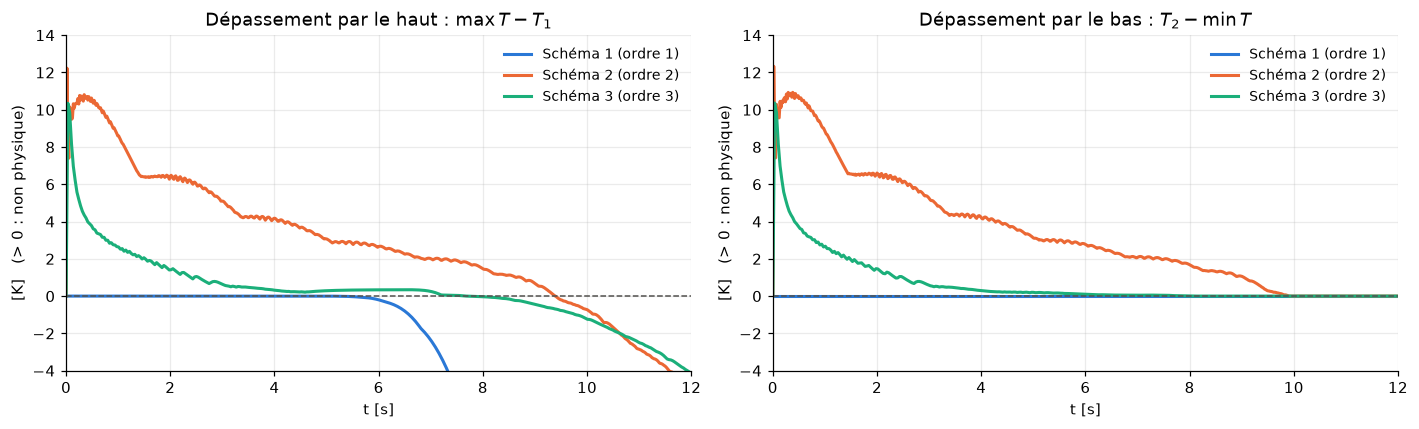

Schéma 1 (ordre 1) : dépassement max =   0.00 K à t =  0.00 s ; dépassement > 0.5 K jusqu'à t =  0.00 s
Schéma 2 (ordre 2) : dépassement max =  12.33 K à t =  0.02 s ; dépassement > 0.5 K jusqu'à t =  9.37 s
Schéma 3 (ordre 3) : dépassement max =  10.36 K à t =  0.03 s ; dépassement > 0.5 K jusqu'à t =  3.34 s


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for m, r in res65.items():
    axes[0].plot(r["t"], r["T_max"] - T1, color=COLORS[m], lw=2, label=NAMES[m])
    axes[1].plot(r["t"], T2 - r["T_min"], color=COLORS[m], lw=2, label=NAMES[m])
axes[0].set_title(r"Dépassement par le haut : $\max T - T_1$")
axes[1].set_title(r"Dépassement par le bas : $T_2 - \min T$")
for ax in axes:
    ax.axhline(0, color=COLORS["ref"], ls="--", lw=1)
    ax.set_xlim(0, 12); ax.set_ylim(-4, 14)
    ax.set_xlabel("t [s]"); ax.set_ylabel("[K]   (> 0 : non physique)")
    ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

for m, r in res65.items():
    over = np.maximum(r["T_max"] - T1, T2 - r["T_min"])
    k_peak = np.argmax(over)
    late = r["t"][over > 0.5]
    t_end = late[-1] if late.size else 0.0
    print(f"{NAMES[m]} : dépassement max = {over[k_peak]:6.2f} K à t = {r['t'][k_peak]:5.2f} s ; "
          f"dépassement > 0.5 K jusqu'à t = {t_end:5.2f} s")

**Lecture.**

- Le dépassement est **maximal dès le premier pas de temps** (~12 K pour le schéma 2, ~10 K
  pour le schéma 3). Il naît sur la **discontinuité initiale** : un saut de 100 K sur une seule
  maille contient toutes les longueurs d'onde jusqu'à l'échelle de la maille, exactement
  celles que ces schémas propagent mal (section 2.6). C'est l'analogue numérique du
  **phénomène de Gibbs**.
- Il **décroît ensuite régulièrement** : la diffusion physique, et la dissipation numérique
  aux petites échelles, amortissent les modes de maille, et le front s'épaissit jusqu'à être
  résolu par plusieurs mailles. Le schéma 3 s'en débarrasse en ~3 s, le schéma 2 en ~9 s. On
  retrouve ce que montrait l'analyse de von Neumann : le schéma 2 est le plus dispersif. Le
  schéma 3, grâce à son hyperdiffusion, « nettoie » plus vite les petites échelles.
- Après ~10 s, plus aucune trace : les résultats finaux ne sont pas pollués. Mais **tout
  résultat aux temps courts (< 10 s) des schémas 2/3 contient ces quelques kelvins d'erreur
  non physique** à 65×65. C'est précisément la fenêtre où se produit $\Phi_w^{max}$…
- C'est le **théorème de Godunov** en action : ordre élevé + schéma linéaire = oscillations
  près des discontinuités. Pour les supprimer, il faudrait un schéma **non linéaire**
  (limiteur de pente MUSCL/TVD, WENO…), au prix d'une perte locale de précision.

### 3.1 Évolution du champ de température (schéma 3)

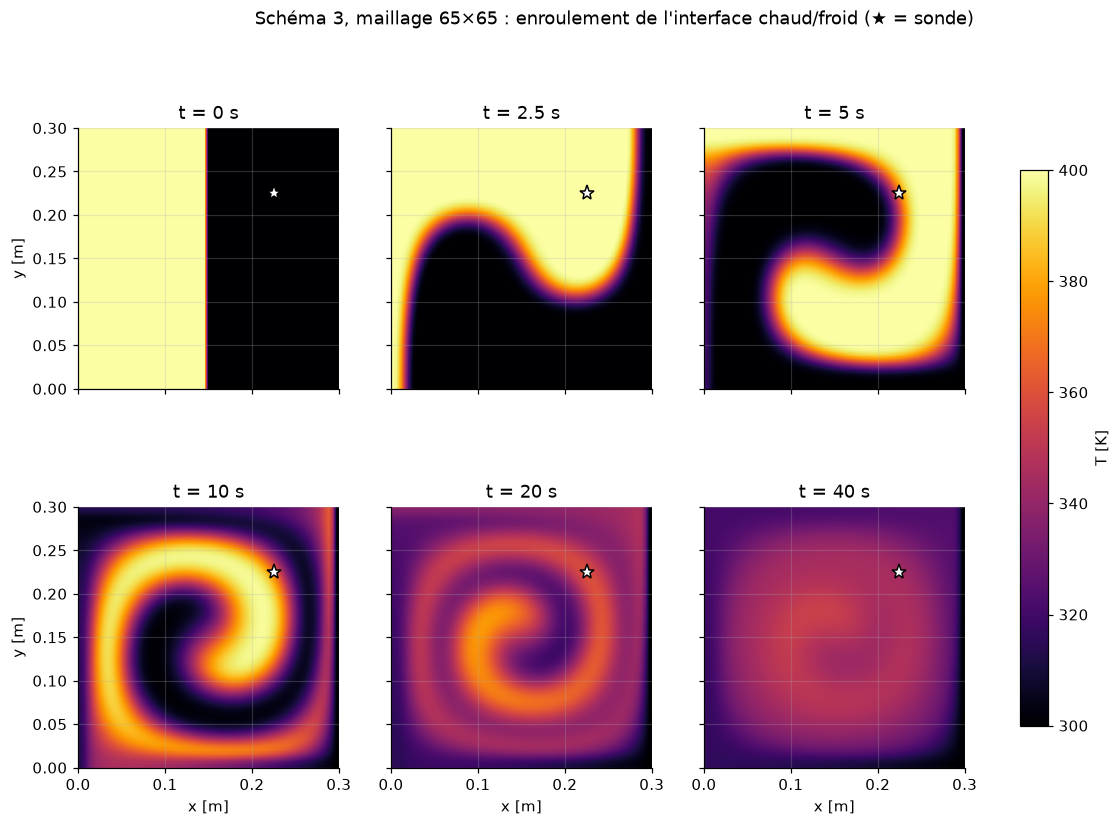

In [15]:
r = res65[3]
fig, axes = plt.subplots(2, 3, figsize=(13, 8.2), sharex=True, sharey=True)
for ax, ts in zip(axes.flat, SNAP_TIMES):
    im = ax.imshow(r["snapshots"][ts], origin="lower", extent=(0, L, 0, L),
                   cmap=CMAP_T, vmin=T2, vmax=T1, interpolation="bilinear")
    ax.set_title(f"t = {ts:g} s")
    ax.plot(3 * L / 4, 3 * L / 4, marker="*", ms=10, color="w", mec="k")
for ax in axes[1]:
    ax.set_xlabel("x [m]")
for ax in axes[:, 0]:
    ax.set_ylabel("y [m]")
fig.colorbar(im, ax=axes, label="T [K]", shrink=0.8)
fig.suptitle("Schéma 3, maillage 65×65 : enroulement de l'interface chaud/froid (★ = sonde)")
plt.show()

**Lecture physique, image par image.**

- **t = 0 → 5 s** : le tourbillon (horaire) fait monter le fluide chaud le long de la paroi
  gauche, le long du haut, puis le fait **descendre le long de la paroi droite froide** (déjà
  bien visible à 2.5 s). Le fluide froid, lui, est chassé vers le bas puis vers la gauche.
  L'interface bascule et commence à s'enrouler. Entre 3 et 10 s, la paroi droite est
  « léchée » par du fluide à ~400 K : c'est la période où le flux pariétal culmine.
- **t = 10 → 20 s** : l'interface s'enroule en **spirale**. Les bras de la spirale
  s'amincissent (étirement), donc les gradients s'intensifient, et la diffusion devient
  efficace : les couleurs intermédiaires (orange) apparaissent, le fluide se **mélange**.
- **t = 40 s** : la spirale est largement diffusée ; il reste un cœur chaud tournant lentement
  (au centre, la vitesse est faible : seul la diffusion y agit) et une couche refroidie le long
  de la paroi droite (**couche limite thermique**).
- Le fluide qui longe la paroi droite est refroidi, puis réinjecté dans le tourbillon par le
  bas : la paroi droite est « **un puits de chaleur alimenté par le tourbillon** ».

### 3.2 Comparaison des trois schémas

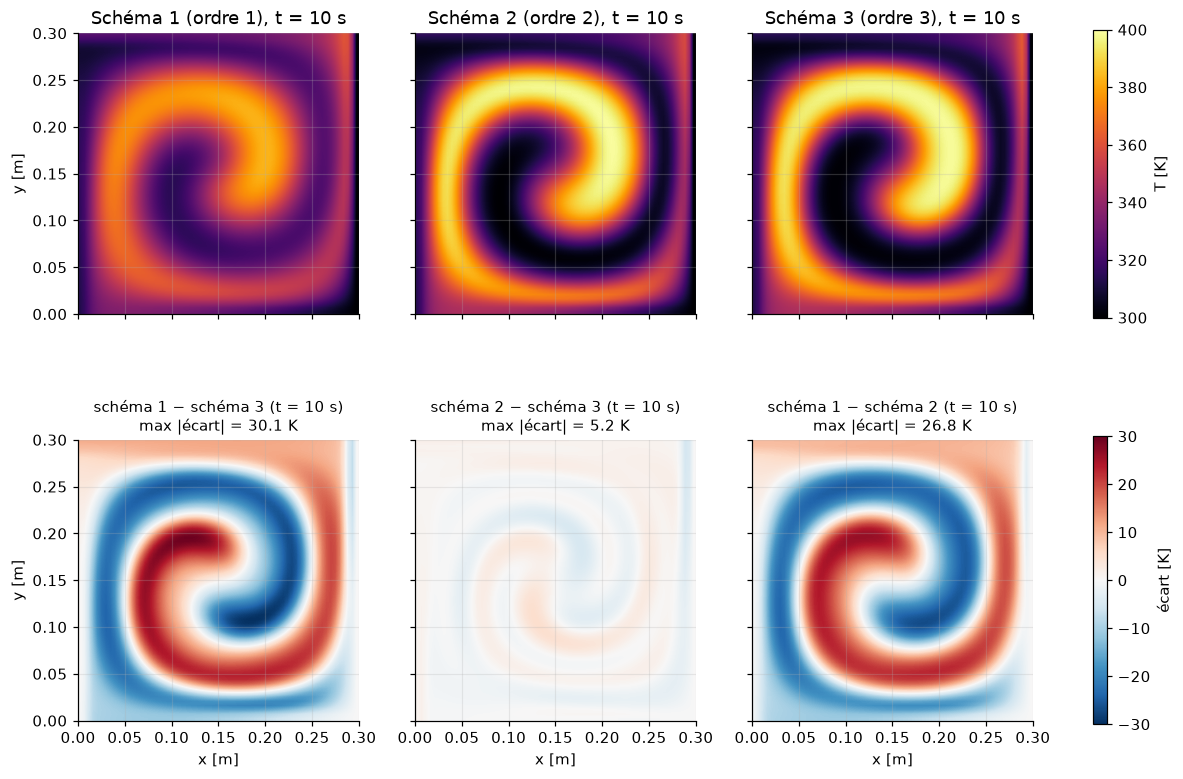

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.8), sharex=True, sharey=True)
for col, m in enumerate((1, 2, 3)):
    im = axes[0, col].imshow(res65[m]["snapshots"][10.0], origin="lower", extent=(0, L, 0, L),
                             cmap=CMAP_T, vmin=T2, vmax=T1, interpolation="bilinear")
    axes[0, col].set_title(f"{NAMES[m]}, t = 10 s")
fig.colorbar(im, ax=axes[0], label="T [K]", shrink=0.85)

# Écarts par rapport au schéma 3 (le plus précis a priori), échelle divergente symétrique
lim = 30
for col, (m_a, m_b) in enumerate(((1, 3), (2, 3), (1, 2))):
    diff = res65[m_a]["snapshots"][10.0] - res65[m_b]["snapshots"][10.0]
    im2 = axes[1, col].imshow(diff, origin="lower", extent=(0, L, 0, L),
                              cmap=CMAP_DIFF, vmin=-lim, vmax=lim, interpolation="bilinear")
    axes[1, col].set_title(f"schéma {m_a} − schéma {m_b} (t = 10 s)\nmax |écart| = {np.abs(diff).max():.1f} K",
                           fontsize=10)
fig.colorbar(im2, ax=axes[1], label="écart [K]", shrink=0.85)
for ax in axes[1]:
    ax.set_xlabel("x [m]")
for ax in axes[:, 0]:
    ax.set_ylabel("y [m]")
plt.show()

**Lecture.**

- **Schéma 1** : la spirale est **floue**, ses bras sont épais et fusionnent. C'est l'image
  directe de la diffusion numérique ($D_{num}\approx 10\,D$). Physiquement, on simule un
  fluide qui conduit la chaleur dix fois trop bien.
- **Schémas 2 et 3** : spirales nettes et très proches. Leur écart est localisé **sur les
  fronts** (là où les gradients sont forts, donc là où l'erreur de troncature est grande),
  avec une alternance rouge/bleu qui traduit un **léger décalage de position** des fronts :
  c'est l'erreur de **dispersion** (phase), pas d'amplitude.
- L'écart 1 − 3 est de plusieurs dizaines de kelvins, l'écart 2 − 3 de quelques kelvins.
  Le maillage 65×65 est donc **acceptable pour les schémas d'ordre élevé, mais pas pour le
  schéma 1**.

### 3.3 Température à la sonde et flux pariétal au cours du temps

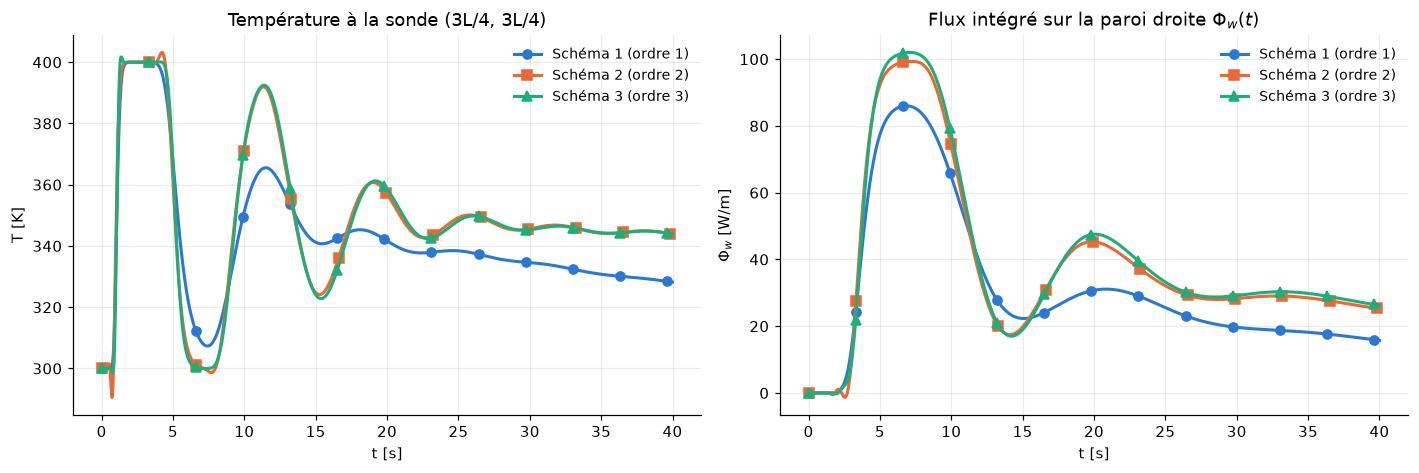

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for m, r in res65.items():
    axes[0].plot(r["t"], r["probe"], color=COLORS[m], lw=2, label=NAMES[m],
                 marker=MARKERS[m], markevery=max(1, r["n_steps"] // 12), ms=6)
    axes[1].plot(r["t"], r["Phi"], color=COLORS[m], lw=2, label=NAMES[m],
                 marker=MARKERS[m], markevery=max(1, r["n_steps"] // 12), ms=6)
axes[0].set_title("Température à la sonde (3L/4, 3L/4)")
axes[0].set_xlabel("t [s]"); axes[0].set_ylabel("T [K]")
axes[1].set_title(r"Flux intégré sur la paroi droite $\Phi_w(t)$")
axes[1].set_xlabel("t [s]"); axes[1].set_ylabel(r"$\Phi_w$ [W/m]")
for ax in axes:
    ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

**Lecture — sonde.**

- Pendant la première seconde, la sonde est dans le fluide froid ($T=300$ K). Puis le
  **front chaud arrive** (il a longé le haut du domaine) et $T$ monte brusquement à ~400 K. Juste
  avant, on voit le **petit creux non physique** du schéma 2 (sous 300 K) : c'est l'oscillation
  de la section 3.0 qui précède le front.
- Ensuite, les **bras successifs de la spirale** passent sur la sonde (fluide froid vers 6-8 s,
  de nouveau chaud vers 11 s…) : on voit des oscillations (alternance chaud/froid), qui
  s'amortissent avec le mélange. La sonde tend
  vers une valeur proche de ~345 K, la température « mélangée » locale.
- Le schéma 1 lisse ces oscillations : il a déjà détruit les structures fines de la spirale.

**Lecture — flux.**

- $\Phi_w(0)=0$, puis montée rapide quand le fluide chaud atteint la paroi, **maximum vers
  $t\approx7$ s**, puis décroissance : le fluide qui arrive sur la paroi est de moins en moins
  chaud (déjà mélangé, déjà refroidi).
- Les trois maxima sont **différents de ±10 %** : le pic correspond au moment où un front
  **raide** frappe la paroi. Le flux est une **dérivée à la paroi** ; il dépend directement de
  la raideur du front, donc de sa résolution. On l'avait prévu à la section 1.3
  ($\delta\approx$ 1 maille).

### 3.4 Contrôle par le bilan d'énergie

**Ce qu'on regarde** : $\Phi_w$ calculé par le gradient à la paroi vs
$\Phi_w^E=-\rho c_p\,dE/dt$. Ce sont deux mesures de la **même** grandeur physique.

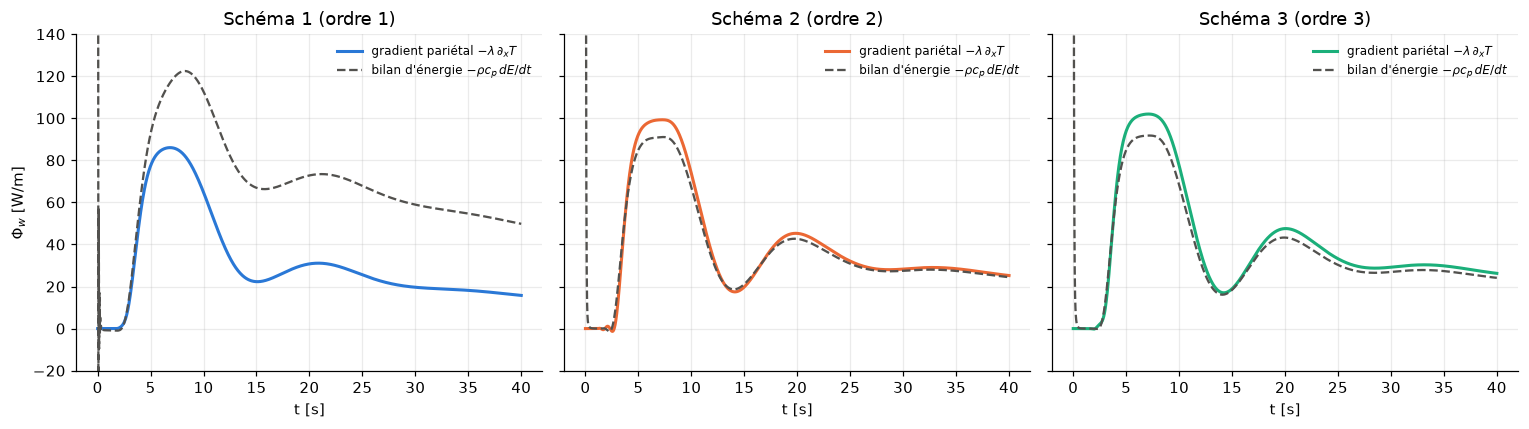

Schéma 1 (ordre 1) : chaleur évacuée en 40 s =    2710 J/m (sur 5344 J/m d'excès initial)   Phi_max : paroi  86.05 / bilan 122.48 W/m ; pic du bilan pour t < 1 s :  890 W/m
Schéma 2 (ordre 2) : chaleur évacuée en 40 s =    1515 J/m (sur 5344 J/m d'excès initial)   Phi_max : paroi  99.30 / bilan  91.09 W/m ; pic du bilan pour t < 1 s :  643 W/m
Schéma 3 (ordre 3) : chaleur évacuée en 40 s =    1496 J/m (sur 5344 J/m d'excès initial)   Phi_max : paroi 102.02 / bilan  91.80 W/m ; pic du bilan pour t < 1 s :  466 W/m


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (m, r) in zip(axes, res65.items()):
    ax.plot(r["t"], r["Phi"], color=COLORS[m], lw=2, label=r"gradient pariétal $-\lambda\,\partial_x T$")
    ax.plot(r["t"], r["Phi_E"], color=COLORS["ref"], lw=1.5, ls="--", label=r"bilan d'énergie $-\rho c_p\, dE/dt$")
    ax.set_title(NAMES[m]); ax.set_xlabel("t [s]")
    ax.set_ylim(-20, 140)
    ax.legend(fontsize=8)
axes[0].set_ylabel(r"$\Phi_w$ [W/m]")
plt.tight_layout(); plt.show()

for m, r in res65.items():
    lost = rho_cp * (r["E"][0] - r["E"][-1])
    print(f"{NAMES[m]} : chaleur évacuée en 40 s = {lost:7.0f} J/m "
          f"(sur {rho_cp * (r['E'][0] - T2 * L**2):.0f} J/m d'excès initial)   "
          f"Phi_max : paroi {r['Phi_max']:6.2f} / bilan {r['Phi_E_max']:6.2f} W/m ; "
          f"pic du bilan pour t < 1 s : {r['Phi_E'][r['t'] < 1.0].max():4.0f} W/m")

**Lecture : un diagnostic très parlant.**

- **Le pic à $t\approx0$** (coupé sur la figure : plusieurs centaines de W/m !) n'a rien de
  physique : à $t=0$, la paroi droite ne voit que du fluide à $T_2$. Ce pic se produit pendant
  les tout premiers pas de temps, quand la discontinuité initiale (non résolue) est advectée
  par $u$. C'est là que l'erreur de conservation (expliquée ci-dessous) est maximale, car elle
  est proportionnelle aux gradients. Elle s'éteint dès que le front est lissé. Pour cette
  raison, on ne cherche le maximum de $\Phi_w^E$ que pour $t\ge1$ s.
- **Schémas 2 et 3** : au-delà, les deux courbes suivent la même évolution, mais avec un écart
  d'environ 10 % au pic (≈ 91 W/m par le bilan contre 99-102 W/m par le gradient). À ce maillage
  grossier, les deux mesures ne sont donc pas encore d'accord. Cet écart doit disparaître quand
  on raffine : on le vérifiera à l'étape 5, où elles coïncident à 0.01 % près.
- **Schéma 1** : les deux « flux » n'ont **rien à voir**. Le bilan d'énergie indique une perte
  de chaleur bien supérieure à ce qui sort réellement par la paroi. Pourquoi ? Nous avons
  discrétisé la forme **advective** $u\,\partial_xT+v\,\partial_yT$, équivalente à la forme
  conservative *dans le continu seulement* (section 1.2). Discrètement, l'opérateur
  d'advection **n'est pas exactement conservatif** : il crée ou détruit de l'énergie, en
  $O(\Delta x^p)$. Pour le schéma 1 ($p=1$, gros gradients mal résolus), cette fuite est
  énorme. Pour les schémas 2 et 3, elle est petite, et elle doit disparaître quand on raffine
  (on le vérifiera).
- **Leçon pratique** : en CFD, **toujours vérifier les bilans globaux**. Un écart entre deux
  évaluations de la même grandeur est un indicateur d'erreur gratuit, sans solution exacte.

---
# 4. Convergence en maillage

## 4.1 Méthode

**Problème** : on n'a **pas de solution analytique**. Comment mesurer l'erreur ?

**Solution** : on calcule une **solution de référence** sur un maillage beaucoup plus fin, avec
le schéma le plus précis (schéma 3, $N=512$, soit 513×513 nœuds), et on la traite comme
« exacte ». C'est légitime à condition que son erreur soit **négligeable devant les erreurs
qu'on veut mesurer** (on le vérifiera a posteriori : l'erreur du schéma 3 diminue d'un facteur
~8 à chaque raffinement, la référence est donc ~8 fois plus précise que le meilleur maillage
testé).

**Maillages emboîtés** : $N=32, 64, 128, 256$ (ratio de raffinement $r=2$). Comme les maillages
sont aux nœuds et emboîtés, chaque nœud grossier existe dans le maillage fin :
`T_ref[::s, ::s]` avec $s=512/N$ donne la référence **aux mêmes points**, sans interpolation.

**Mesures d'erreur** :
- erreur globale sur le champ final : $e_N=\sqrt{\frac{1}{(N+1)^2}\sum_{i,j}(T_{i,j}-T^{ref}_{i,j})^2}$ (norme L2 discrète, en K) ;
- erreurs sur les quantités d'intérêt : $T_{sonde}(40\,s)$, $\Phi_w(40\,s)$, $\Phi_w^{max}$.

**Ordre observé** : si $e\approx C\,\Delta x^p$, alors entre deux maillages successifs
$$p_{obs}=\frac{\ln(e_N/e_{2N})}{\ln 2}.$$
Sur un graphe log-log ($e$ vs $\Delta x$), on doit voir des **droites de pente $p$**.

**Pourquoi le temps n'interfère pas** : $\Delta t\propto\Delta x$ (ou $\Delta x^2$ sur les maillages
fins), et chaque schéma a un ordre en temps égal à son ordre en espace. L'erreur temporelle
décroît donc au moins aussi vite que l'erreur spatiale : l'ordre mesuré est bien l'ordre
**spatial** (au pire, la somme des deux erreurs, de même ordre).

In [19]:
N_conv = [32, 64, 128, 256]
N_ref = 512

t0 = time.perf_counter()
ref = run_simulation(N_ref, 3, interface_value=T_MID)
print(f"Référence (schéma 3, N = {N_ref}) : {ref['n_steps']} pas, CPU = {ref['cpu']:.0f} s "
      f"(temps total {time.perf_counter() - t0:.0f} s)")
print(f"  T_sonde(40s) = {ref['probe_final']:.4f} K,  Phi_w(40s) = {ref['Phi_final']:.4f} W/m,  "
      f"Phi_max = {ref['Phi_max']:.4f} W/m à t = {ref['t_Phi_max']:.2f} s")

Référence (schéma 3, N = 512) : 20531 pas, CPU = 121 s (temps total 128 s)
  T_sonde(40s) = 344.5564 K,  Phi_w(40s) = 24.2237 W/m,  Phi_max = 93.3073 W/m à t = 7.17 s


*Note* : la référence est calculée avec $T=(T_1+T_2)/2$ au nœud d'interface. Ce choix ne change
**pas** le problème continu (une valeur en un seul point ne change pas une fonction de carré
intégrable, ni la solution de l'EDP pour $t>0$). On comprendra à la section 4.3 pourquoi ce
choix est le bon pour une référence.

## 4.2 Premier essai : condition initiale « à la lettre » ($T=T_2$ sur le nœud d'interface)

**Prédiction** : droites de pentes 1, 2 et 3.

(20 s de calcul)

Erreur L2 du champ T(40 s) [K]
                            N=32        N=64       N=128       N=256   ordres observés
Schéma 1 (ordre 1)     1.985e+01   1.233e+01   6.953e+00   3.728e+00    0.69   0.83   0.90
Schéma 2 (ordre 2)     2.658e+00   9.866e-01   4.507e-01   2.158e-01    1.43   1.13   1.06
Schéma 3 (ordre 3)     1.461e+00   7.824e-01   4.075e-01   2.066e-01    0.90   0.94   0.98


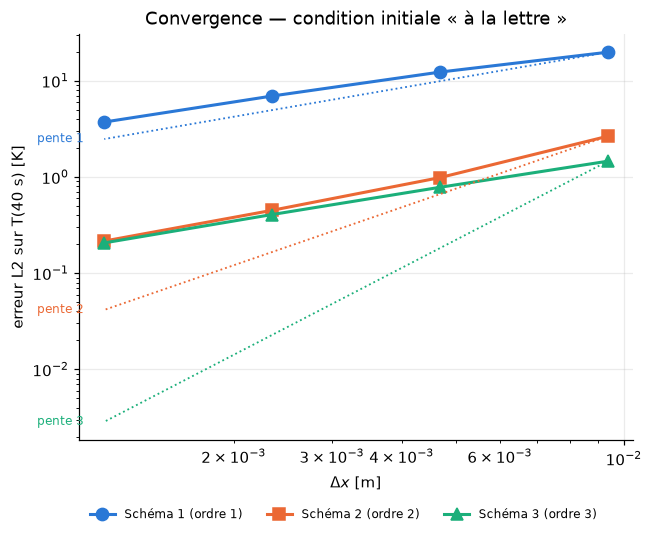

In [20]:
def restrict(T_fine, N_coarse):
    # Extrait du champ fin les noeuds communs avec le maillage grossier (maillages emboîtés)
    s = (T_fine.shape[0] - 1) // N_coarse
    return T_fine[::s, ::s]


def convergence_table(results, ref):
    # Calcule erreurs et ordres observés pour chaque schéma ; renvoie un dict d'erreurs
    errors = {}
    for m in (1, 2, 3):
        e = {"field": [], "probe": [], "Phi": [], "Phi_max": []}
        for N_c in N_conv:
            r = results[(m, N_c)]
            e["field"].append(np.sqrt(np.mean((r["T"] - restrict(ref["T"], N_c))**2)))
            e["probe"].append(abs(r["probe_final"] - ref["probe_final"]))
            e["Phi"].append(abs(r["Phi_final"] - ref["Phi_final"]))
            e["Phi_max"].append(abs(r["Phi_max"] - ref["Phi_max"]))
        errors[m] = {k: np.array(v) for k, v in e.items()}
    return errors


def print_orders(errors, key, label):
    print(f"\n{label}")
    print(f"{'':<20}" + "".join(f"{'N=' + str(n):>12}" for n in N_conv) + "   ordres observés")
    for m in (1, 2, 3):
        e = errors[m][key]
        p = np.log(e[:-1] / e[1:]) / np.log(2)
        print(f"{NAMES[m]:<20}" + "".join(f"{v:12.3e}" for v in e) + "   " + "  ".join(f"{v:5.2f}" for v in p))


def plot_convergence(errors, key, title, ax):
    dxs = L / np.array(N_conv)
    for m in (1, 2, 3):
        ax.loglog(dxs, errors[m][key], color=COLORS[m], marker=MARKERS[m], ms=8, lw=2, label=NAMES[m])
    # pentes théoriques, ancrées sur le point le plus grossier du schéma correspondant
    for p_th in (1, 2, 3):
        e0 = errors[p_th][key][0]
        ax.loglog(dxs, e0 * (dxs / dxs[0])**p_th, color=COLORS[p_th], ls=":", lw=1.2)
        ax.text(dxs[-1] * 0.92, e0 * (dxs[-1] / dxs[0])**p_th, f"pente {p_th}",
                color=COLORS[p_th], fontsize=8, ha="right", va="center")
    ax.set_xlabel(r"$\Delta x$ [m]"); ax.set_title(title)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0.0, -0.14), ncol=3)


t0 = time.perf_counter()
res_step = {(m, N_c): run_simulation(N_c, m, interface_value=T2) for m in (1, 2, 3) for N_c in N_conv}
print(f"({time.perf_counter() - t0:.0f} s de calcul)")
err_step = convergence_table(res_step, ref)
print_orders(err_step, "field", "Erreur L2 du champ T(40 s) [K]")

fig, ax = plt.subplots(figsize=(6.5, 4.8))
plot_convergence(err_step, "field", "Convergence — condition initiale « à la lettre »", ax)
ax.set_ylabel("erreur L2 sur T(40 s) [K]")
plt.show()

**Surprise !** Le schéma 1 a bien une pente proche de 1. Mais les schémas 2 et 3 **aussi** :
leurs ordres observés tendent vers **1** et leurs courbes deviennent presque **confondues** sur
les maillages fins. Le schéma 3 n'est **pas** d'ordre 3, ni même d'ordre 2. Il n'est même pas
meilleur que le schéma 2 !

Ne pas balayer ce résultat sous le tapis (comme au projet 1, avec la condition de Neumann) :
quand **tous** les schémas finissent par converger au même ordre, c'est que l'erreur ne vient
**pas** des schémas eux-mêmes, mais d'un **ingrédient commun**. Les candidats : les conditions aux
limites (on a montré qu'elles sont exactes), le post-traitement (pas en cause pour l'erreur
sur le champ), et… **la condition initiale**, qui est discontinue.

## 4.3 Diagnostic : la valeur du nœud d'interface

Le nœud en $x=L/2$ « représente » la bande $[L/2-\Delta x/2,\ L/2+\Delta x/2]$, dont **une moitié
est chaude et l'autre froide**. En lui donnant $T_2$, on retire une demi-bande de fluide chaud :
la **quantité de chaleur initiale** du calcul est fausse, d'une erreur $\propto\Delta x$. Comme le
domaine est presque fermé (seule la paroi droite échange), cette erreur ne disparaît pas :
elle reste « dans » la solution pendant toute la simulation, et elle décroît seulement **comme
$\Delta x$**, quel que soit l'ordre du schéma.

**Vérification directe** : on compare la chaleur initiale discrète $\iint T\,dA$ (Simpson) à la
valeur exacte $(T_1+T_2)L^2/2$, pour les deux choix de valeur d'interface.

In [21]:
E0_exact = 0.5 * (T1 + T2) * L**2
print(f"{'N':>5} | {'erreur sur E0 (T_interface = T2)':>34} | {'erreur sur E0 (T_interface = (T1+T2)/2)':>40}")
print("-" * 86)
for N_c in N_conv:
    dx_c, _, X_c, _, _, _ = build_grid(N_c)
    for val, store in ((T2, "a"), (T_MID, "b")):
        T_c = initial_condition(X_c, val)
        err = abs(heat_content(T_c, dx_c, N_c) - E0_exact) / E0_exact
        if store == "a":
            err_a = err
        else:
            err_b = err
    print(f"{N_c:5d} | {err_a:34.2e} | {err_b:40.2e}")

    N |   erreur sur E0 (T_interface = T2) |  erreur sur E0 (T_interface = (T1+T2)/2)
--------------------------------------------------------------------------------------
   32 |                           2.98e-03 |                                 0.00e+00
   64 |                           1.49e-03 |                                 0.00e+00
  128 |                           7.44e-04 |                                 0.00e+00
  256 |                           3.72e-04 |                                 0.00e+00


**Lecture.** Avec $T_2$ au nœud d'interface, l'erreur sur la chaleur initiale décroît
**exactement comme $1/N$** (ordre 1). Avec la **moyenne $(T_1+T_2)/2$**, elle est nulle à la
précision machine près.

C'est le bon choix : une discontinuité située sur un nœud doit recevoir la **valeur moyenne** de
part et d'autre. C'est la valeur moyenne de la fonction sur la « cellule » du nœud, comme le
ferait naturellement une méthode de volumes finis. Ce n'est pas un « réglage » pour obtenir le
bon résultat : la fonction $T(x,y,0)$ n'est de toute façon pas définie de façon significative
en un point de mesure nulle. Le problème continu est **le même**, seule sa représentation discrète
est meilleure.

> **Leçon générale.** L'ordre d'un schéma est une promesse qui suppose une solution *régulière*.
> Une donnée initiale discontinue mal représentée suffit à ramener n'importe quel schéma à
> l'ordre 1. Toujours se demander : *ma condition initiale est-elle représentée à l'ordre de
> mon schéma ?*

## 4.4 Second essai : interface à $(T_1+T_2)/2$

**Prédiction** : on doit maintenant retrouver les pentes 1, 2, 3.

(20 s de calcul)

Erreur L2 du champ T(40 s) [K]
                            N=32        N=64       N=128       N=256   ordres observés
Schéma 1 (ordre 1)     1.941e+01   1.196e+01   6.727e+00   3.608e+00    0.70   0.83   0.90
Schéma 2 (ordre 2)     2.216e+00   5.527e-01   1.541e-01   4.087e-02    2.00   1.84   1.92
Schéma 3 (ordre 3)     5.910e-01   9.017e-02   1.210e-02   1.397e-03    2.71   2.90   3.11

Erreur sur T_sonde(40 s) [K]
                            N=32        N=64       N=128       N=256   ordres observés
Schéma 1 (ordre 1)     2.520e+01   1.593e+01   8.956e+00   4.729e+00    0.66   0.83   0.92
Schéma 2 (ordre 2)     1.265e-01   2.547e-03   1.094e-02   5.954e-03    5.63  -2.10   0.88
Schéma 3 (ordre 3)     4.330e-01   7.727e-02   1.056e-02   1.222e-03    2.49   2.87   3.11


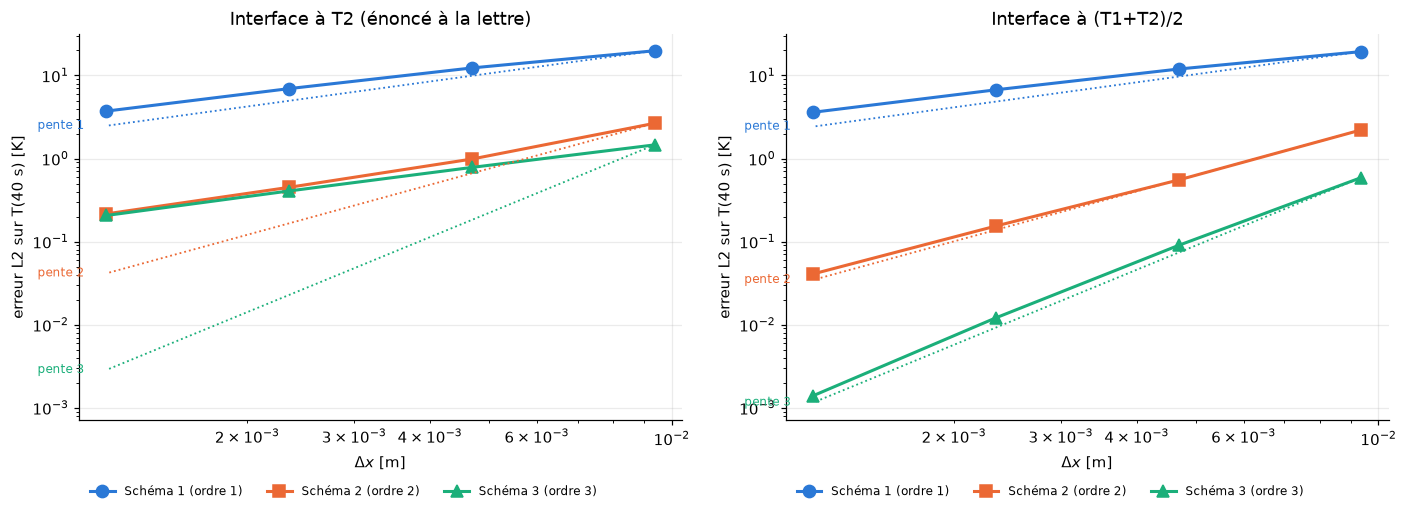

In [22]:
t0 = time.perf_counter()
res_mid = {(m, N_c): run_simulation(N_c, m, interface_value=T_MID) for m in (1, 2, 3) for N_c in N_conv}
print(f"({time.perf_counter() - t0:.0f} s de calcul)")
err_mid = convergence_table(res_mid, ref)
print_orders(err_mid, "field", "Erreur L2 du champ T(40 s) [K]")
print_orders(err_mid, "probe", "Erreur sur T_sonde(40 s) [K]")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
plot_convergence(err_step, "field", "Interface à T2 (énoncé à la lettre)", axes[0])
plot_convergence(err_mid, "field", "Interface à (T1+T2)/2", axes[1])
for ax in axes:
    ax.set_ylabel("erreur L2 sur T(40 s) [K]")
ymin = min(axes[0].get_ylim()[0], axes[1].get_ylim()[0]); ymax = max(axes[0].get_ylim()[1], axes[1].get_ylim()[1])
for ax in axes:
    ax.set_ylim(ymin, ymax)
plt.tight_layout(); plt.show()

**Lecture : le résultat attendu est maintenant au rendez-vous.**

- **Schéma 1** : pente → **1** (elle augmente encore légèrement, signe qu'on n'est pas
  encore tout à fait dans le régime asymptotique : l'erreur est si grande sur les maillages
  grossiers que le développement de Taylor n'est pas encore valable).
- **Schéma 2** : pente ≈ **2**.
- **Schéma 3** : pente ≈ **3**. Diviser $\Delta x$ par 2 divise l'erreur par ~8.

Les trois schémas sont donc **convergents** et ont l'**ordre annoncé**, à condition de
représenter correctement la condition initiale. C'est la vérification demandée par l'énoncé.

**Ordres de grandeur pratiques** (erreur L2 à 65×65) : le schéma 1 se trompe de ~12 K, le
schéma 2 de ~0.5 K, le schéma 3 de ~0.1 K. À $N=256$, le schéma 1 a encore 3.6 K d'erreur :
pire que le schéma 3 sur le maillage 33×33 !

L'erreur sur la sonde (seconde table) suit le même comportement pour les schémas 1 et 3. Le
schéma 2 y est plus erratique : une seule valeur ponctuelle peut bénéficier d'une
**compensation d'erreurs fortuite** (à $N=64$, l'erreur passe par presque zéro parce qu'elle
change de signe). C'est pour cela qu'on juge l'ordre sur une **norme globale**, plus robuste.

## 4.5 Et le flux pariétal ?


Erreur sur Phi_w(40 s) [W/m]
                            N=32        N=64       N=128       N=256   ordres observés
Schéma 1 (ordre 1)     1.220e+01   8.269e+00   5.674e+00   3.253e+00    0.56   0.54   0.80
Schéma 2 (ordre 2)     1.369e+00   1.267e+00   2.010e-01   8.902e-02    0.11   2.66   1.18
Schéma 3 (ordre 3)     8.926e+00   2.320e+00   2.453e-03   1.503e-02    1.94   9.89  -2.62

Erreur sur Phi_w^max [W/m]
                            N=32        N=64       N=128       N=256   ordres observés
Schéma 1 (ordre 1)     7.603e+00   7.210e+00   7.659e+00   4.473e+00    0.08  -0.09   0.78
Schéma 2 (ordre 2)     5.146e+00   6.006e+00   5.066e-01   2.641e-01   -0.22   3.57   0.94
Schéma 3 (ordre 3)     3.416e+01   8.731e+00   4.294e-02   6.467e-02    1.97   7.67  -0.59


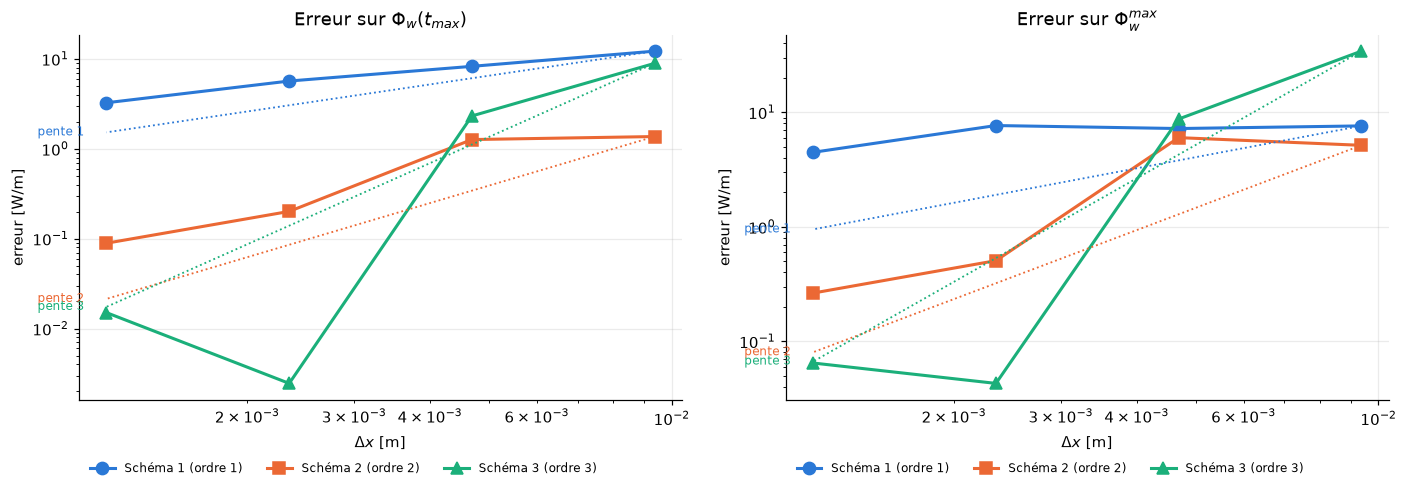

In [23]:
print_orders(err_mid, "Phi", "Erreur sur Phi_w(40 s) [W/m]")
print_orders(err_mid, "Phi_max", "Erreur sur Phi_w^max [W/m]")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
plot_convergence(err_mid, "Phi", r"Erreur sur $\Phi_w(t_{max})$", axes[0])
plot_convergence(err_mid, "Phi_max", r"Erreur sur $\Phi_w^{max}$", axes[1])
for ax in axes:
    ax.set_ylabel("erreur [W/m]")
plt.tight_layout(); plt.show()

**Lecture : le flux converge beaucoup moins sagement que le champ.**

- Sur les maillages grossiers ($N=32, 64$), les erreurs sur $\Phi_w$ des schémas 2 et 3 sont
  **grandes (plusieurs %) et irrégulières**. On est **hors du régime asymptotique** : le front
  qui frappe la paroi a une épaisseur $\delta\approx5$ mm, soit 1 à 2 mailles. Un développement
  de Taylor n'a aucun sens tant que la structure n'est pas résolue par plusieurs points.
- À partir de $N=128$ ($\delta/\Delta x\approx2$), l'erreur chute brutalement : pour le schéma 3,
  $\Phi_w^{max}$ est à moins de 0.1 % de la référence.
- Les points des schémas 2 et 3 à $N\ge128$ sont si proches de la référence qu'on atteint le
  **niveau d'erreur de la référence elle-même**. L'ordre « observé » n'y est plus fiable (il
  peut même devenir négatif). C'est une limite de la méthode : on ne peut pas mesurer une
  erreur plus petite que celle de l'étalon.
- **Schéma 1** : erreur de l'ordre de 5 à 10 %, qui diminue à peine. Il est inutilisable pour
  le flux.

**Leçon** : l'ordre d'un schéma est une propriété **asymptotique**. Les quantités qui dépendent
des **gradients** (flux, frottement pariétal…) exigent des maillages beaucoup plus fins que
les quantités « intégrales » ou ponctuelles. Un maillage « convergé » pour la température ne
l'est pas forcément pour le flux.

---
# 5. Valeur de $\Phi_w^{max}$ et intervalle de confiance

**Objectif** : donner $\Phi_w^{max}$ sous la forme « valeur ± incertitude », **sans connaître la
solution exacte**. On croise plusieurs sources d'information indépendantes.

**Outil 1 — Extrapolation de Richardson / GCI** (Roache). Si $f_h\approx f_{exact}+C\,h^p$, deux
maillages $h$ et $h/2$ donnent
$$f_{ext}=f_{h/2}+\frac{f_{h/2}-f_h}{2^p-1},\qquad
\mathrm{GCI}=F_s\,\frac{|f_{h/2}-f_h|}{2^p-1},\quad F_s=1.25 .$$
Le GCI est une estimation (avec un coefficient de sécurité $F_s$) de l'erreur restante sur le
maillage fin. On peut l'utiliser seulement si l'on est dans le régime asymptotique, avec un $p$ connu
(ici $p=3$, vérifié à la section 4.4).

**Outil 2 — Écart entre schémas** : schémas 2 et 3 au même maillage fin.

**Outil 3 — Écart entre définitions** : gradient pariétal vs bilan d'énergie.

On ajoute pour cela le schéma 2 à $N=512$ (≈ 2 min de calcul).

In [24]:
t0 = time.perf_counter()
ref_s2 = run_simulation(N_ref, 2, interface_value=T_MID)
print(f"Schéma 2, N = 512 : CPU = {ref_s2['cpu']:.0f} s")

all_runs = {**res_mid, (3, 512): ref, (2, 512): ref_s2}
print(f"\n{'':<20}{'N':>5} {'Phi_max (paroi)':>16} {'Phi_max (bilan E)':>18} {'t(Phi_max)':>11}")
for m in (2, 3):
    for N_c in (64, 128, 256, 512):
        r = all_runs[(m, N_c)]
        print(f"{NAMES[m]:<20}{N_c:5d} {r['Phi_max']:16.4f} {r['Phi_E_max']:18.4f} {r['t_Phi_max']:11.3f}")

Schéma 2, N = 512 : CPU = 89 s

                        N  Phi_max (paroi)  Phi_max (bilan E)  t(Phi_max)
Schéma 2 (ordre 2)     64          99.3129            91.1107       7.266
Schéma 2 (ordre 2)    128          92.8007            93.1899       7.267
Schéma 2 (ordre 2)    256          93.0432            93.3574       7.187
Schéma 2 (ordre 2)    512          93.2595            93.3349       7.173
Schéma 3 (ordre 3)     64         102.0383            91.8158       7.089
Schéma 3 (ordre 3)    128          93.2644            93.1073       7.184
Schéma 3 (ordre 3)    256          93.2426            93.2879       7.170
Schéma 3 (ordre 3)    512          93.3073            93.3110       7.168


In [25]:
f128, f256, f512 = (all_runs[(3, n)]["Phi_max"] for n in (128, 256, 512))
fE128, fE256, fE512 = (all_runs[(3, n)]["Phi_E_max"] for n in (128, 256, 512))

# Ordre observé sur trois maillages (sans référence) : p = ln[(f128 - f256)/(f256 - f512)] / ln 2
for name, (a, b, c) in (("paroi", (f128, f256, f512)), ("bilan E", (fE128, fE256, fE512))):
    ratio = (a - b) / (b - c)
    p_txt = f"{np.log(ratio) / np.log(2):.2f}" if ratio > 0 else "non défini (convergence non monotone)"
    print(f"Schéma 3, Phi_max ({name:7s}) : écarts {a - b:+.4f}, {b - c:+.4f}  ->  ordre observé = {p_txt}")

p = 3
Phi_ext = f512 + (f512 - f256) / (2**p - 1)
GCI = 1.25 * abs(f512 - f256) / (2**p - 1)
spread_schemes = abs(f512 - all_runs[(2, 512)]["Phi_max"])
spread_defs = abs(f512 - fE512)

print(f"\nRichardson (p = 3, maillages 256/512) : Phi_ext = {Phi_ext:.4f} W/m, GCI = {GCI:.4f} W/m")
print(f"Écart schéma 3 / schéma 2 à N = 512     : {spread_schemes:.4f} W/m")
print(f"Écart paroi / bilan d'énergie (s3, 512) : {spread_defs:.4f} W/m")

half_width = max(GCI, spread_schemes, spread_defs)
print(f"\n==> Phi_w^max = {f512:.2f} ± {half_width:.2f} W/m   "
      f"(± {100 * half_width / f512:.2f} %), atteint à t ≈ {ref['t_Phi_max']:.2f} s")

Schéma 3, Phi_max (paroi  ) : écarts +0.0217, -0.0647  ->  ordre observé = non défini (convergence non monotone)
Schéma 3, Phi_max (bilan E) : écarts -0.1806, -0.0231  ->  ordre observé = 2.97

Richardson (p = 3, maillages 256/512) : Phi_ext = 93.3165 W/m, GCI = 0.0115 W/m
Écart schéma 3 / schéma 2 à N = 512     : 0.0478 W/m
Écart paroi / bilan d'énergie (s3, 512) : 0.0037 W/m

==> Phi_w^max = 93.31 ± 0.05 W/m   (± 0.05 %), atteint à t ≈ 7.17 s


**Construction de l'intervalle, pas à pas.**

1. **Ordre observé sur 3 maillages.** Pour le $\Phi_w^{max}$ « pariétal », les écarts successifs
   changent de signe : la convergence n'est **pas monotone** à ce niveau de précision (quelques
   centièmes de W/m). On ne peut pas en tirer d'ordre. Pour le $\Phi_w^{max}$ par **bilan
   d'énergie**, la convergence est monotone et l'ordre observé est proche de 3. Cela conforte
   l'hypothèse $p=3$ utilisée dans Richardson.
2. **GCI** avec $p=3$ : quelques centièmes de W/m.
3. Les deux autres indicateurs (écart entre schémas, écart entre définitions du flux) sont du
   même ordre ou un peu plus grands. On retient **le plus pessimiste** des trois : c'est un
   intervalle de confiance « pratique », comme demandé, robuste plutôt qu'optimiste.

**Résultat** : $\Phi_w^{max}\approx 93.3$ W/m, à $\pm0.05$ W/m près environ (soit < 0.1 %),
atteint à $t\approx7.2$ s. Le tableau ci-dessous replace les résultats 65×65 dans cet intervalle.

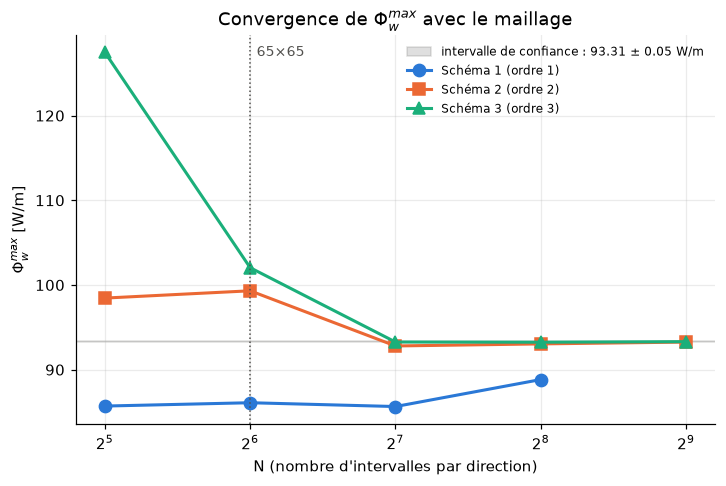

Au maillage 65x65 (interface (T1+T2)/2) :
  Schéma 1 (ordre 1) : Phi_max =   86.10 W/m  ->  écart à la valeur convergée :   -7.7 %
  Schéma 2 (ordre 2) : Phi_max =   99.31 W/m  ->  écart à la valeur convergée :   +6.4 %
  Schéma 3 (ordre 3) : Phi_max =  102.04 W/m  ->  écart à la valeur convergée :   +9.4 %


In [26]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.axhspan(f512 - half_width, f512 + half_width, color=COLORS["ref"], alpha=0.18,
           label=rf"intervalle de confiance : {f512:.2f} ± {half_width:.2f} W/m")
for m in (1, 2, 3):
    Ns = [n for n in (32, 64, 128, 256, 512) if (m, n) in all_runs]
    ax.semilogx(Ns, [all_runs[(m, n)]["Phi_max"] for n in Ns], color=COLORS[m],
                marker=MARKERS[m], ms=8, lw=2, base=2, label=NAMES[m])
ax.axvline(64, color=COLORS["ref"], ls=":", lw=1)
ax.text(66, ax.get_ylim()[1] * 0.99, "65×65", va="top", fontsize=9, color=COLORS["ref"])
ax.set_xlabel("N (nombre d'intervalles par direction)")
ax.set_ylabel(r"$\Phi_w^{max}$ [W/m]")
ax.set_title(r"Convergence de $\Phi_w^{max}$ avec le maillage")
ax.legend(fontsize=8)
plt.show()

print(f"Au maillage 65x65 (interface (T1+T2)/2) :")
for m in (1, 2, 3):
    v = res_mid[(m, 64)]["Phi_max"]
    print(f"  {NAMES[m]} : Phi_max = {v:7.2f} W/m  ->  écart à la valeur convergée : {100 * (v - f512) / f512:+6.1f} %")

**Lecture.** À 65×65, **aucun** schéma ne donne $\Phi_w^{max}$ à mieux que ~6 % : le schéma 1
**sous-estime** (front trop étalé, gradient pariétal trop faible), les schémas 2 et 3
**surestiment** (leurs erreurs dispersives raidissent un peu le front au moment de l'impact). Il
faut au moins $N=128$ avec le schéma 2 ou 3 pour entrer dans l'intervalle à quelques dixièmes
de % près. Le schéma 1 n'y entre pas, même à $N=256$.

---
# 6. Performance : coût à précision égale

**La bonne question n'est pas** « quel schéma est le plus rapide par pas de temps ? » (réponse
évidente : le schéma 1). **C'est** : « quel schéma atteint une précision donnée pour le moindre
coût ? »

**Ce qu'on trace** : l'erreur L2 sur le champ en fonction du temps CPU, pour chaque schéma et
chaque maillage. La meilleure méthode est la courbe **la plus en bas à gauche**.

**Prédiction théorique.** Coût $\propto$ (nb de nœuds) × (nb de pas) × (nb d'étapes RK) $\propto N^2\cdot N\cdot s = N^3$
(régime advectif), et erreur $\propto N^{-p}$. Donc **erreur $\propto$ coût$^{-p/3}$** : pentes −1/3,
−2/3, −1 en log-log. Plus l'ordre est élevé, plus la pente est raide, donc plus l'avantage
grandit quand on exige de la précision.

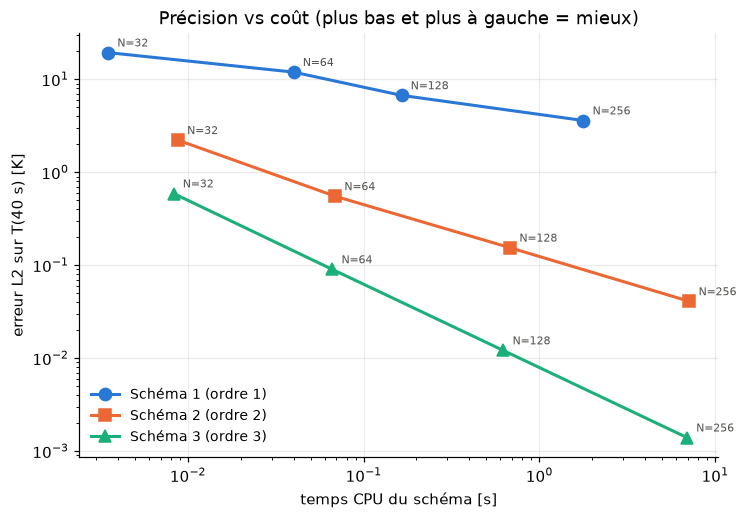

 erreur cible |         Schéma 1 (ordre 1) |         Schéma 2 (ordre 2) |         Schéma 3 (ordre 3)
----------------------------------------------------------------------------------------------------
       1.00 K |          241 s (EXTRAPOLÉ) |       0.0286 s (interpolé) |      0.00462 s (interpolé)
       0.10 K |     1.61e+06 s (EXTRAPOLÉ) |         1.47 s (interpolé) |       0.0592 s (interpolé)
       0.01 K |     1.08e+10 s (EXTRAPOLÉ) |         86.1 s (EXTRAPOLÉ) |        0.772 s (interpolé)


In [27]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for m in (1, 2, 3):
    cpus = np.array([res_mid[(m, n)]["cpu"] for n in N_conv])
    errs = err_mid[m]["field"]
    ax.loglog(cpus, errs, color=COLORS[m], marker=MARKERS[m], ms=8, lw=2, label=NAMES[m])
    for n, c, e in zip(N_conv, cpus, errs):
        ax.annotate(f"N={n}", (c, e), textcoords="offset points", xytext=(6, 4), fontsize=7,
                    color=COLORS["ref"])
ax.set_xlabel("temps CPU du schéma [s]")
ax.set_ylabel("erreur L2 sur T(40 s) [K]")
ax.set_title("Précision vs coût (plus bas et plus à gauche = mieux)")
ax.legend(fontsize=9)
plt.show()


def cost_for_error(m, target):
    # Interpole / extrapole en log-log (sur les deux maillages les plus fins) le CPU
    # nécessaire pour atteindre une erreur L2 cible avec le schéma m.
    cpus = np.array([res_mid[(m, n)]["cpu"] for n in N_conv])
    errs = err_mid[m]["field"]
    slope = np.log(cpus[-1] / cpus[-2]) / np.log(errs[-1] / errs[-2])
    if errs[-1] <= target:  # interpolation dans les données mesurées
        k = np.argmax(errs <= target)
        slope = np.log(cpus[k] / cpus[k - 1]) / np.log(errs[k] / errs[k - 1])
        return cpus[k] * (target / errs[k])**slope, "interpolé"
    return cpus[-1] * (target / errs[-1])**slope, "EXTRAPOLÉ"


print(f"{'erreur cible':>13} | " + " | ".join(f"{NAMES[m]:>26}" for m in (1, 2, 3)))
print("-" * 100)
for target in (1.0, 0.1, 0.01):
    cells = []
    for m in (1, 2, 3):
        c, how = cost_for_error(m, target)
        cells.append(f"{c:12.3g} s ({how:>9})")
    print(f"{target:11.2f} K | " + " | ".join(f"{c:>26}" for c in cells))

**Lecture.**

- **À précision égale, le schéma 3 gagne, et de très loin.** Pour une erreur de 0.1 K, il faut
  ~0.07 s au schéma 3, ~1.7 s au schéma 2 (25 fois plus), et un temps astronomique
  (extrapolé, donc à prendre comme un ordre de grandeur) au schéma 1.
- Le schéma 1 n'est « rapide » que pour des précisions grossières, qu'aucun ingénieur
  n'accepterait ici (~10 K d'erreur).
- **Le coût par pas ne dit rien** : le schéma 3 fait 3 évaluations du second membre par pas,
  avec des stencils plus larges. Mais il peut utiliser un $\Delta t$ deux fois plus grand que le
  schéma 2, et surtout un maillage **beaucoup plus grossier** pour la même précision. Comme
  le coût croît en $N^3$ (voire $N^4$), gagner un facteur 2 sur $N$ fait gagner un facteur 8 à 16
  sur le temps.
- Les pentes mesurées sont plus faibles que la prédiction ($-p/3$) sur les maillages fins. C'est
  la contrainte de **diffusion explicite** ($\Delta t\propto\Delta x^2$) qui commence à dominer
  à $N=256$ (section 2.6) : le coût passe progressivement de $N^3$ à $N^4$. Sur des maillages
  encore plus fins, traiter la diffusion **implicitement** (schéma IMEX) serait le prochain gain
  important.
- *Remarque* : les temps sur les petits maillages (quelques millisecondes) sont dominés par les
  frais fixes (appels de fonctions Python) et sont donc peu significatifs. Les conclusions
  reposent sur les maillages moyens et fins.

---
# 7. Synthèse

In [28]:
print("Résultats sur le maillage 65x65 (interface à (T1+T2)/2), comparés aux valeurs convergées\n")
print(f"{'':<22}{'T_sonde(40s) [K]':>18}{'Phi_w(40s) [W/m]':>18}{'Phi_max [W/m]':>16}{'CPU [s]':>10}")
print("-" * 84)
for m in (1, 2, 3):
    r = res_mid[(m, 64)]
    print(f"{NAMES[m]:<22}{r['probe_final']:18.3f}{r['Phi_final']:18.3f}{r['Phi_max']:16.3f}{r['cpu']:10.3f}")
print(f"{'Référence (s3, N=512)':<22}{ref['probe_final']:18.3f}{ref['Phi_final']:18.3f}{ref['Phi_max']:16.3f}{ref['cpu']:10.1f}")
print(f"\nPhi_w^max = {f512:.2f} ± {half_width:.2f} W/m, atteint à t ≈ {ref['t_Phi_max']:.2f} s")

Résultats sur le maillage 65x65 (interface à (T1+T2)/2), comparés aux valeurs convergées

                        T_sonde(40s) [K]  Phi_w(40s) [W/m]   Phi_max [W/m]   CPU [s]
------------------------------------------------------------------------------------
Schéma 1 (ordre 1)               328.624            15.955          86.097     0.040
Schéma 2 (ordre 2)               344.559            25.491          99.313     0.069
Schéma 3 (ordre 3)               344.634            26.543         102.038     0.066
Référence (s3, N=512)            344.556            24.224          93.307     120.7

Phi_w^max = 93.31 ± 0.05 W/m, atteint à t ≈ 7.17 s


### Réponses aux éléments obligatoires du sujet

**1. Trois schémas convergents d'ordres différents.**

| | Construction | Propriétés |
|---|---|---|
| Schéma 1 | upwind 1 + diffusion centrée 2 + Euler | monotone (pas de dépassement), stable si $\mathrm{CFL}+4\mathrm{Fo}\le1$, **très diffusif** ($D_{num}\approx10D$ à 65×65) |
| Schéma 2 | upwind 2 (3 points) + diffusion centrée 2 + RK2 (Heun) | erreur **dispersive** ($\partial_{xxx}$), non monotone (Godunov), pas de temps le plus restrictif ($\sigma\le0.5$) |
| Schéma 3 | upwind-biaisé 3 (4 points) + diffusion centrée 4 + RK3-SSP | erreur **hyperdiffusive** ($\partial_{xxxx}$), qui amortit seulement les petites échelles ; $\sigma\le1$ |

Ordres mesurés : **≈ 1, 2 et 3**, conformes à la théorie. Il faut pour cela :
- des conditions aux limites traitées exactement (nœuds fantômes symétriques) ;
- un post-traitement d'ordre 4 ;
- **une condition initiale correctement représentée** ($T=(T_1+T_2)/2$ sur le nœud de la
  discontinuité). Sinon, tous les schémas sont ramenés à l'ordre ~1.

**2. Résultats 65×65.** Spirale de mélange bien capturée par les schémas 2 et 3, fortement
lissée par le schéma 1. $T_{sonde}(40\,s)\approx344.6$ K (schémas 2/3) contre ~329 K (schéma 1).
Le flux $\Phi_w$ culmine vers $t\approx7$ s, quand le front chaud frappe la paroi froide. À 65×65,
le flux n'est **pas convergé** (erreur ≥ 6 % sur $\Phi_w^{max}$ pour tous les schémas). La raison
est physique : l'épaisseur d'équilibre des filaments $\delta=\sqrt{D/\gamma}\approx5$ mm vaut à
peine une maille.

**3. Convergence en maillage.** Voir section 4. La température converge vite ; le flux,
quantité de gradient, demande $N\ge128$.

**4. $\Phi_w^{max}\approx93.3\pm0.05$ W/m**, à $t\approx7.2$ s. L'intervalle combine Richardson/GCI
($p=3$), l'écart entre schémas et l'écart entre deux définitions indépendantes du flux (gradient
pariétal / bilan d'énergie).

**5. Performance.** À précision égale, **le schéma d'ordre 3 est de loin le plus économique**.
Le schéma 1 est disqualifié dès qu'on veut une précision de l'ordre du kelvin. Sur maillage très
fin, la diffusion explicite devient le facteur limitant ($\Delta t\propto\Delta x^2$).

### Ce qu'il faut retenir (au-delà de ce TP)

1. **Estimer les nombres sans dimension avant de coder** : $Pe$, $Pe_{\Delta x}$, $\delta/\Delta x$
   ont prédit presque tout ce qu'on a observé.
2. **Un ordre de convergence se vérifie, il ne se suppose pas.** Le maillon le plus faible
   (CL, condition initiale, post-traitement) fixe l'ordre de toute la chaîne.
3. **L'ordre est asymptotique.** Tant que les structures physiques ne sont pas résolues par
   plusieurs mailles, l'erreur ne suit pas $C\Delta x^p$.
4. **Toujours croiser les estimations** (bilans globaux, plusieurs schémas, plusieurs
   maillages) pour donner un résultat avec son incertitude.
5. **Haute précision = économie**, dès que la précision demandée est sérieuse.